# Análisis exploratorio de datos: bajo peso al nacer en el Perú

**Inteligencia Artificial Aplicada (1INF62) — Pontificia Universidad Católica del Perú, 2026-2**

**Integrantes:** Aguilera, Jair · Araujo, Luis · Condori, Nilton · Vilcayauri, Pedro


---

### Abstract

Este notebook presenta el análisis exploratorio del registro de Certificados de Nacido Vivo (CNV) del Ministerio de Salud, con corte al 30 de noviembre de 2025: **4 874 510 nacimientos registrados entre 2015 y 2025**. El objetivo es caracterizar el dataset, evaluar su calidad y fundamentar las decisiones de preprocesamiento para predecir el bajo peso al nacer (< 2500 g) con información disponible antes del parto.

En calidad de datos, se repararon 388 filas cuyo separador estaba corrupto y se encontró que `Hijos_fallec_madre` tiene 97% de valores `-1` sin que el formulario ofrezca la opción 0, lo que vuelve ambiguo su significado; la variable se excluyó. `Estado_Civil` resultó poco confiable: 85% figura como "soltero" y el 79% de las madres de 17 años o menos tiene el campo vacío. El peso presenta redondeo de dígitos, con 3.5 veces más registros en exactamente 2500 g que en 2490 g, y 0.6% de los registros declara más hijos vivos que embarazos sin que se trate de un parto múltiple.

La prevalencia de bajo peso es **6.38%** (desbalance ≈ 1:15), por lo que accuracy no es una métrica válida. El factor prenatal más fuerte es el embarazo múltiple (58% de bajo peso en partos dobles frente a 5.5% en únicos). Le siguen el departamento de residencia, la edad materna (con relación en forma de U), el nivel de instrucción, el financiador del parto y el país de origen de la madre, que no estaba en la lista inicial de features. Ninguna variable prenatal supera por sí sola un AUC de 0.58, mientras que la duración del embarazo alcanza 0.89; esto justifica evaluarla en un escenario separado (B) y anticipa un rendimiento modesto en el escenario prenatal (A).

### Estructura del notebook

1. Configuración del entorno
2. Carga y reparación del dataset
3. Descripción general
   - 3.1 Rol de cada variable y evidencia de leakage
4. Calidad de datos
   - 4.1 Códigos de valor faltante
   - 4.2 Semántica de `-1` en la historia obstétrica
   - 4.3 Valores fuera de rango
   - 4.4 Duplicados
   - 4.5 Consistencia entre variables
   - 4.6 Consistencia de `Estado_Civil`
   - 4.7 Limpieza mínima para el análisis
5. Análisis del target
6. Análisis univariado de las features
7. Análisis bivariado: features vs bajo peso
   - 7.1 Features vs peso al nacer (regresión)
8. Relaciones entre features
9. Justificación de los escenarios A y B
10. Conclusiones y decisiones de preprocesamiento

## 1. Configuración del entorno

El notebook funciona tanto en Google Colab como en local. En Colab clona o actualiza el repositorio; en local asume que se ejecuta desde `proyecto/notebooks/`.

In [ ]:
import sys, io, zipfile, tempfile, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/jasnai10/AI_Project.git"

if IN_COLAB:
    if not Path("/content/AI_Project").exists():
        !git clone -q {REPO_URL} /content/AI_Project
    else:
        !git -C /content/AI_Project pull -q
    ROOT = Path("/content/AI_Project/proyecto")
else:
    ROOT = Path.cwd().parent

RAW_ZIP = ROOT / "data" / "raw" / "dataset.zip"
URL_ZIP = "https://raw.githubusercontent.com/jasnai10/AI_Project/main/proyecto/data/raw/dataset.zip"
CSV_FIX = Path(tempfile.gettempdir()) / "cnv_reparado.csv"   # fuera del repo: pesa ~830 MB

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

GUARDAR_FIGURAS = False
FIG_DIR = ROOT / "notebooks" / "figuras_eda"

def guardar(nombre):
    plt.tight_layout()
    if GUARDAR_FIGURAS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / f"eda_{nombre}.png", dpi=120, bbox_inches="tight")
    plt.show()

print("Entorno:", "Colab" if IN_COLAB else "local", "| ROOT:", ROOT)

Entorno: Colab | ROOT: /content/AI_Project/proyecto


## 2. Carga y reparación del dataset

El archivo original usa `;` como separador, pero algunas ocupaciones contienen `;` en el texto (por ejemplo, `VENDEDOR AMBULANTE; COSMETICOS, PERFUMES...`). Esas filas quedan con 23 campos en lugar de 22 y todas las columnas a la derecha de `DESC_OCUPACION` se desplazan una posición, incluida `Financiador_Parto`.

La función `reparar_csv` lee el CSV línea por línea, une los fragmentos sobrantes dentro de `DESC_OCUPACION` y escribe una versión reparada. No se descarta ninguna fila. Esta misma lógica se replica en `src/preprocessing.py`.

In [ ]:
def obtener_zip(ruta=RAW_ZIP, url=URL_ZIP):
    """Usa el ZIP del repo; si no existe o es un puntero de Git LFS, lo descarga."""
    if ruta.exists():
        with open(ruta, "rb") as f:
            if f.read(2) == b"PK":
                return ruta
    import requests
    destino = Path(tempfile.gettempdir()) / "dataset.zip"
    r = requests.get(url, timeout=600); r.raise_for_status()
    if not r.content.startswith(b"PK"):
        raise ValueError(f"La URL no devolvió un ZIP: {r.content[:80]!r}")
    destino.write_bytes(r.content)
    return destino


def reparar_csv(zip_path, out_csv, sep=";", col_libre="DESC_OCUPACION"):
    """Une los ';' sobrantes dentro de la columna de texto libre. Devuelve un reporte."""
    with zipfile.ZipFile(zip_path) as z:
        nombre = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
        with z.open(nombre) as fin, open(out_csv, "w", encoding="utf-8", newline="") as fout:
            lector = io.TextIOWrapper(fin, encoding="utf-8-sig", newline="")
            header = lector.readline().rstrip("\r\n").split(sep)
            n, idx = len(header), header.index(col_libre)
            fout.write(sep.join(header) + "\n")
            rep = {"archivo": nombre, "filas": 0, "reparadas": 0, "descartadas": 0,
                   "campos_por_fila": Counter(), "ejemplos": []}
            for linea in lector:
                campos = linea.rstrip("\r\n").split(sep)
                rep["campos_por_fila"][len(campos)] += 1
                extra = len(campos) - n
                if extra > 0:
                    texto = ", ".join(c.strip() for c in campos[idx: idx + extra + 1])
                    if len(rep["ejemplos"]) < 3:
                        rep["ejemplos"].append({"original": linea.strip(), "ocupacion_reparada": texto})
                    campos = campos[:idx] + [texto] + campos[idx + extra + 1:]
                    rep["reparadas"] += 1
                elif extra < 0:
                    rep["descartadas"] += 1
                    continue
                fout.write(sep.join(campos) + "\n")
                rep["filas"] += 1
    return rep


reporte_carga = reparar_csv(obtener_zip(), CSV_FIX)
print("Archivo:", reporte_carga["archivo"])
print("Número de campos por fila en el CSV original:", dict(reporte_carga["campos_por_fila"]))
print(f"Filas reparadas: {reporte_carga['reparadas']} | descartadas: {reporte_carga['descartadas']} | filas finales: {reporte_carga['filas']:,}")
print("\nEjemplos de filas con ';' dentro de la ocupación:")
for ej in reporte_carga["ejemplos"]:
    print("  ORIGINAL :", ej["original"])
    print("  REPARADA :", ej["ocupacion_reparada"], "\n")

# Todo se carga como 'category': 4.9 M filas ocupan ~140 MB en lugar de varios GB
df = pd.read_csv(CSV_FIX, sep=";", dtype="category")
print(f"Shape: {df.shape} | Memoria: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

Archivo: CNV_MINSA_CORTE_30112025.csv
Número de campos por fila en el CSV original: {22: 4874122, 23: 388}
Filas reparadas: 388 | descartadas: 0 | filas finales: 4,874,510

Ejemplos de filas con ';' dentro de la ocupación:
  ORIGINAL : 2023;08;3615;51.5;40;EUTOCICO;MASCULINO;UNICO;29;SOLTERO;SECUNDARIA COMPLETA;VENDEDOR AMBULANTE; COSMETICOS, PERFUMES, LOCION, ETC.;2;2;-1;NINGUNO; PERU ;150133;8741;ESTABLECIMIENTO DE SALUD;OBSTETRA;ESSALUD
  REPARADA : VENDEDOR AMBULANTE, COSMETICOS, PERFUMES, LOCION, ETC. 

  ORIGINAL : 2025;11;2545;49.5;41;EUTOCICO;MASCULINO;UNICO;20;SOLTERO;SECUNDARIA COMPLETA;VENDEDOR AMBULANTE; ESCOBAS, ESCOBILLAS, ESCOBILLONES, ETC.;2;1;-1;1; PERU ;080910;2469;ESTABLECIMIENTO DE SALUD;OBSTETRA;SIS
  REPARADA : VENDEDOR AMBULANTE, ESCOBAS, ESCOBILLAS, ESCOBILLONES, ETC. 

  ORIGINAL : 2017;11;4415;53  ;40;CESAREA;MASCULINO;UNICO;34;CASADO;SECUNDARIA COMPLETA;VENDEDOR AMBULANTE; ACEITE PARA AUTOS, LUBRICANTES (ENVASAD;3;3;-1;NINGUNO; PERU ;040129;13291;ESTABLECIMIE

In [ ]:
# Validación del fix: la columna siguiente a la ocupación (Num_embar_madre) tiene un dominio conocido
validos = {"-1", "1", "2", "3", "4", ">=5"}
fuera = (~df["Num_embar_madre"].astype(str).str.strip().isin(validos)).sum()
print("Filas con Num_embar_madre fuera de dominio tras la reparación:", fuera)
df.head()

Filas con Num_embar_madre fuera de dominio tras la reparación: 0


,FecNac_Año,FecNac_Mes,PESO_NACIDO,TALLA_NACIDO,DUR_EMB_PARTO,Condicion_Parto,sexo_nacido,Tipo_Parto,Edad_Madre,Estado_Civil,Nivel_Intrucción_Madre,DESC_OCUPACION,Num_embar_madre,Hijos_vivo_madre,Hijos_fallec_madre,nacmuer_abort_madre,Pais_Madre,IdUbigeoInei,Ipress,Lugar_Nacido,Atiende_Parto,Financiador_Parto
0,2021,08,3620,52,40,EUTOCICO,MASCULINO,UNICO,34,SOLTERO,SECUNDARIA COMPLETA,AMA DE CASA,3,2,-1,1,PERU,150121,6211,ESTABLECIMIENTO DE SALUD,OBSTETRA,SIS
1,2021,08,3850,52,41,CESAREA,MASCULINO,UNICO,43,SOLTERO,SECUNDARIA COMPLETA,AMA DE CASA,>=5,>=5,-1,NINGUNO,PERU,130101,8685,ESTABLECIMIENTO DE SALUD,MEDICO GINECO-OBSTETRA,ESSALUD
2,2021,08,3005,50,37,CESAREA,FEMENINO,UNICO,27,SOLTERO,SUPERIOR UNIV. COMPLETA,AMA DE CASA,3,2,1,NINGUNO,PERU,210112,3251,ESTABLECIMIENTO DE SALUD,MEDICO GINECO-OBSTETRA,SIS
3,2021,08,3055,49,37,CESAREA,MASCULINO,UNICO,35,SOLTERO,SUPERIOR UNIV. COMPLETA,PSICOLOGO,1,1,-1,NINGUNO,PERU,150122,9682,ESTABLECIMIENTO DE SALUD,MEDICO GINECO-OBSTETRA,PRIVADOS
4,2021,09,3500,50,38,EUTOCICO,FEMENINO,UNICO,33,SOLTERO,SUPERIOR UNIV. COMPLETA,PROFESOR DE ENSEÐANZA PRIMARIA,3,3,-1,NINGUNO,PERU,140118,8577,ESTABLECIMIENTO DE SALUD,OBSTETRA,ESSALUD


**Interpretación.** La distribución de campos por fila confirma el problema: 4 874 122 filas tienen 22 campos y 388 tienen 23. Los ejemplos muestran que el `;` sobrante está dentro de la ocupación. Tras la reparación quedan 4 874 510 registros y 22 columnas, sin descartar ninguna fila. La validación lo confirma: ningún valor de `Num_embar_madre`, la columna siguiente a la ocupación, queda fuera de su dominio. Cargar las columnas como `category` reduce la memoria a ~140 MB, lo que permite trabajar con el dataset completo en Colab.

## 3. Descripción general

In [ ]:
resumen = pd.DataFrame({
    "n_unicos": df.nunique(),
    "valores_mas_frecuentes": [", ".join(map(str, df[c].value_counts().index[:4])) for c in df.columns],
})
resumen

,n_unicos,valores_mas_frecuentes
FecNac_Año,11,"2018, 2019, 2017, 2022"
FecNac_Mes,12,"03, 05, 09, 04"
PESO_NACIDO,5156,"3000, 3200, 3500, 3100"
TALLA_NACIDO,430,"50 , 49 , 51 , 48"
DUR_EMB_PARTO,26,"39, 40, 38, 37"
Condicion_Parto,4,"EUTOCICO, CESAREA, IGNORADO, INSTRUMENTADO"
sexo_nacido,3,"MASCULINO, FEMENINO, IGNORADO"
Tipo_Parto,5,"UNICO, DOBLE, IGNORADO, TRIPLE"
Edad_Madre,61,"28, 29, 27, 26"
Estado_Civil,7,"SOLTERO, CASADO, IGNORADO, CONVIVIENTE"


Registros por año:
FecNac_Año
2015    417413
2016    459738
2017    480488
2018    494034
2019    485271
2020    461754
2021    462658
2022    466046
2023    410495
2024    390092
2025    346521

Registros por mes en 2025:
FecNac_Mes
01    31965
02    30156
03    34188
04    32234
05    32905
06    30776
07    31203
08    31286
09    31966
10    30728
11    29114
12        0


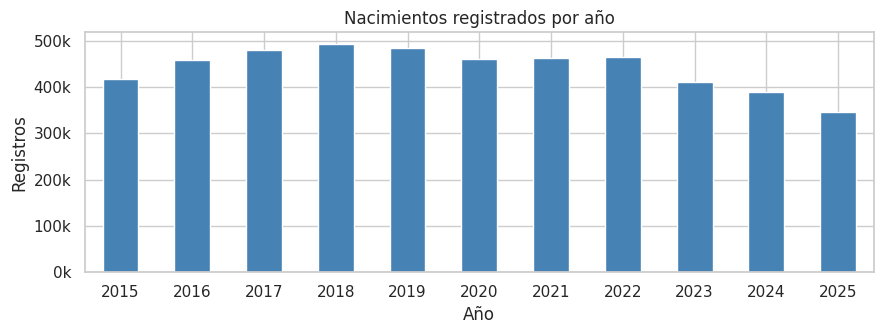

In [ ]:
por_anio = df["FecNac_Año"].value_counts().sort_index()
print("Registros por año:"); print(por_anio.to_string())
print("\nRegistros por mes en 2025:")
print(df.loc[df["FecNac_Año"] == "2025", "FecNac_Mes"].value_counts().sort_index().to_string())
ax = por_anio.plot.bar(figsize=(9, 3.5), color="steelblue", rot=0)
ax.set_title("Nacimientos registrados por año"); ax.set_xlabel("Año"); ax.set_ylabel("Registros")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}k"))
guardar("registros_por_anio")

In [ ]:
# Todas las categorías de las variables de baja cardinalidad (≤ 15 valores)
for c in df.columns:
    if df[c].nunique() <= 15:
        print(f"{c}: {sorted(df[c].cat.categories.astype(str).tolist())}")

FecNac_Año: ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
FecNac_Mes: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
Condicion_Parto: ['CESAREA', 'EUTOCICO', 'IGNORADO', 'INSTRUMENTADO']
sexo_nacido: ['FEMENINO', 'IGNORADO', 'MASCULINO']
Tipo_Parto: ['DOBLE', 'IGNORADO', 'MAS DE TRES', 'TRIPLE', 'UNICO']
Estado_Civil: ['CASADO', 'CONVIVIENTE', 'DIVORCIADO', 'IGNORADO', 'SEPARADO', 'SOLTERO', 'VIUDO']
Nivel_Intrucción_Madre: ['IGNORADO', 'INCIAL/PRE-ESCOLAR', 'NINGUN NIVEL/ILETRADO', 'PRIMARIA COMPLETA', 'PRIMARIA INCOMPLETA', 'SECUNDARIA COMPLETA', 'SECUNDARIA INCOMPLETA', 'SUPERIOR NO UNIV. COMPLETA', 'SUPERIOR NO UNIV. INCOMPLETA', 'SUPERIOR UNIV. COMPLETA', 'SUPERIOR UNIV. INCOMPLETA']
Num_embar_madre: ['-1', '1', '2', '3', '4', '>=5']
Hijos_vivo_madre: ['-1', '1', '2', '3', '4', '>=5']
Hijos_fallec_madre: ['-1', '1', '2', '3', '4', '>=5']
nacmuer_abort_madre: ['1', '10', '11 a más', '2', '3', '4', '5', '6', '7', '

In [ ]:
# Problemas de formato
espacios = {c: int((df[c].cat.categories.astype(str) != df[c].cat.categories.astype(str).str.strip()).sum())
            for c in df.columns}
print("Categorías con espacios al inicio o al final:", {c: v for c, v in espacios.items() if v > 0})
print("Ejemplos:", [repr(x) for x in df["TALLA_NACIDO"].cat.categories[:3]], [repr(x) for x in df["Pais_Madre"].cat.categories[:3]])

ocup = df["DESC_OCUPACION"].astype(str)
mal = ocup.str.contains("Ð")
print(f"\nOcupaciones con el carácter 'Ð' (ñ mal codificada): {mal.sum():,} registros, "
      f"{df.loc[mal, 'DESC_OCUPACION'].nunique()} valores distintos. Ejemplos:")
print(df.loc[mal, "DESC_OCUPACION"].value_counts().head(3).to_string())

ubi = df["IdUbigeoInei"].astype(str).str.strip()
print(f"\nDistritos distintos en IdUbigeoInei (sin contar -1): {ubi[ubi != '-1'].nunique():,}")
print(f"Valores distintos en DESC_OCUPACION: {df['DESC_OCUPACION'].nunique():,}")
print(f"Proporción de 'AMA DE CASA' en DESC_OCUPACION: {(df['DESC_OCUPACION'] == 'AMA DE CASA').mean()*100:.1f}%")
print(f"\nPaíses distintos en Pais_Madre: {df['Pais_Madre'].nunique()}. Los 5 más frecuentes:")
print(df["Pais_Madre"].astype(str).str.strip().value_counts().head(5).to_string())
print(f"Registros con Ipress = 1: {(df['Ipress'].astype(str) == '1').sum():,}")

Categorías con espacios al inicio o al final: {'PESO_NACIDO': 626, 'TALLA_NACIDO': 72, 'DUR_EMB_PARTO': 1, 'Pais_Madre': 122}
Ejemplos: ["'-1'", "'047 '", "'048 '"] ["' ALEMANIA '", "' ARGENTINA '", "' BELICE '"]

Ocupaciones con el carácter 'Ð' (ñ mal codificada): 34,968 registros, 48 valores distintos. Ejemplos:
DESC_OCUPACION
PROFESOR DE ENSEÐANZA PRIMARIA                     27901
DISEÐADOR, GRAFICO                                  1952
PUBLICISTA, RESPONSABLE DE CAMPAÐA PUBLICITARIA     1363

Distritos distintos en IdUbigeoInei (sin contar -1): 1,892
Valores distintos en DESC_OCUPACION: 2,875
Proporción de 'AMA DE CASA' en DESC_OCUPACION: 83.8%

Países distintos en Pais_Madre: 127. Los 5 más frecuentes:
Pais_Madre
PERU         4755336
VENEZUELA     101607
COLOMBIA        3660
BOLIVIA         2463
ECUADOR         1664
Registros con Ipress = 1: 37,655


**Interpretación.** Cada afirmación se apoya en las salidas de las tres celdas anteriores:
- **Cobertura:** el registro cubre 11 años, de 2015 a 2025, con entre 346 mil (2025) y 494 mil (2018) nacimientos por año. 2025 tiene **0 registros en diciembre**, lo que coincide con el corte al 30/11 indicado en el nombre del archivo; por eso ese año tiene menos registros. La caída de 2023 y 2024 no se explica con los datos disponibles. Como el análisis trabaja con tasas, la sección 5 verifica si la prevalencia también cambia en el tiempo.
- **Espacios sobrantes:** afectan a `PESO_NACIDO` (626 categorías), `TALLA_NACIDO` (72) y `Pais_Madre` (122), por ejemplo `'047 '` o `' ALEMANIA '`.
- **Errata:** el nivel de instrucción tiene la categoría `INCIAL/PRE-ESCOLAR`.
- **Codificación:** 34 968 registros de ocupación tienen `Ð` en lugar de `Ñ` (por ejemplo, `ENSEÐANZA`).
- **Cardinalidad:** `DESC_OCUPACION` tiene 2875 valores, con 83.8% en "AMA DE CASA". `IdUbigeoInei` tiene 1892 distritos más el código `-1`, y `Pais_Madre` tiene 127 países, con Perú y Venezuela concentrando casi todos los registros.
- **Código sospechoso no documentado:** 37 655 registros tienen `Ipress = 1`. No afecta al modelo porque `Ipress` se excluye.

### 3.1 Rol de cada variable y evidencia de leakage

| Variable | Rol | Justificación |
|---|---|---|
| `PESO_NACIDO` | **Target** (regresión) y base de `bajo_peso` (clasificación) | Variable a predecir |
| `Edad_Madre`, `Nivel_Intrucción_Madre`, `Financiador_Parto`, `Tipo_Parto`, `sexo_nacido` | Feature (Escenarios A y B) | Conocidas antes del parto |
| `Estado_Civil` | Excluida | Baja validez y faltante dependiente de la edad (ver sección 4.6) |
| `Num_embar_madre`, `nacmuer_abort_madre` | Feature (Escenarios A y B) | Historia obstétrica previa |
| `Hijos_vivo_madre` | Excluida | Redundante con `Num_embar_madre` (ver sección 8) |
| `Hijos_fallec_madre` | Excluida | Significado ambiguo del código `-1` (ver sección 4.2) |
| `IdUbigeoInei` → `departamento` | Feature (Escenarios A y B) | Proxy geográfico (altitud, nivel socioeconómico) |
| `DUR_EMB_PARTO` | Solo Escenario B | Leakage temporal: la edad gestacional se estima durante el embarazo, pero la duración final (si el parto será pretérmino) solo se conoce al nacer (ver sección 9) |
| `TALLA_NACIDO` | Excluida: leakage directo | Medida del recién nacido, simultánea al peso |
| `Condicion_Parto`, `Lugar_Nacido`, `Atiende_Parto` | Excluidas: leakage temporal | Se definen durante el parto, no antes |
| `Pais_Madre` → `pais_grupo` | Feature (Escenarios A y B) | Conocida antes del parto; agrupada en Perú / Venezuela / Otro (ver secciones 4.7 y 7) |
| `DESC_OCUPACION` | Excluida | Texto libre con 2875 valores y 84% concentrado en "AMA DE CASA" (ver sección 3) |
| `Ipress` | Excluida | Identificador del establecimiento de salud: depende de dónde ocurre el parto |
| `FecNac_Año`, `FecNac_Mes` | Excluidas como predictores | Variables de calendario; se usan para analizar la tendencia temporal |

La exclusión de las variables con leakage se decide por **el momento en que se conocen**, no por su asociación con el target. Aun así, la siguiente celda muestra que están fuertemente asociadas al resultado, lo que confirma que incluirlas inflaría artificialmente las métricas.

In [ ]:
peso_tmp = pd.to_numeric(df["PESO_NACIDO"].astype(str).str.strip(), errors="coerce")
talla_tmp = pd.to_numeric(df["TALLA_NACIDO"].astype(str).str.strip(), errors="coerce")
validos_pt = peso_tmp.between(500, 6000) & talla_tmp.between(20, 65)
print(f"Correlación de Spearman entre TALLA_NACIDO y PESO_NACIDO: "
      f"{peso_tmp[validos_pt].corr(talla_tmp[validos_pt], method='spearman'):.3f}")

bp_tmp = (peso_tmp < 2500)[peso_tmp.between(500, 6000)]
for c in ["Condicion_Parto", "Lugar_Nacido", "Atiende_Parto"]:
    t = bp_tmp.groupby(df.loc[bp_tmp.index, c], observed=True).agg(["mean", "count"])
    t.columns = ["tasa_bajo_peso", "n"]; t["tasa_bajo_peso"] *= 100
    print(f"\n{c}:"); print(t.sort_values("tasa_bajo_peso", ascending=False).round(2).to_string())
del peso_tmp, talla_tmp, bp_tmp

Correlación de Spearman entre TALLA_NACIDO y PESO_NACIDO: 0.722

Condicion_Parto:
                 tasa_bajo_peso        n
Condicion_Parto                         
IGNORADO                 10.180    15387
CESAREA                   9.470  1872765
INSTRUMENTADO             5.490     6936
EUTOCICO                  4.410  2976398

Lugar_Nacido:
                          tasa_bajo_peso        n
Lugar_Nacido                                     
VIA PUBLICA                       17.400     2621
IGNORADO                          10.980      246
DOMICILIO                          7.460    57619
ESTABLECIMIENTO DE SALUD           6.370  4780277
CENTRO DE TRABAJO                  4.880     1843
OTRO                               4.720    28880

Atiende_Parto:
                              tasa_bajo_peso        n
Atiende_Parto                                        
NADIE(AUTOAYUDA)                      16.430     2417
FAMILIAR                               9.810    41249
OTRO                     

**Interpretación.**
- `TALLA_NACIDO` tiene una correlación de 0.72 con el peso. Usarla equivaldría a predecir el peso con otra medida del mismo recién nacido.
- Las variables del parto también se asocian fuertemente al resultado: la cesárea tiene 9.5% de bajo peso frente a 4.4% del parto eutócico; el parto en vía pública, 17.4%; y el parto sin asistencia, 16.4%. Parte de esa asociación es causalidad inversa: un feto con bajo peso o prematuro tiene más probabilidad de nacer por cesárea o de ser atendido por un especialista.

Esto confirma la decisión de la tabla anterior: incluir estas variables inflaría las métricas con información que no existe antes del parto.

## 4. Calidad de datos

### 4.1 Códigos de valor faltante

El CNV no usa celdas vacías: los faltantes vienen codificados como `IGNORADO`, `-1` o `99`, según la variable. Por eso `isna()` reporta cero y hay que contarlos explícitamente.

In [ ]:
def contar_codigos(s):
    cats = s.cat.categories.astype(str).str.strip().str.upper()
    t = pd.Series(cats[s.cat.codes.to_numpy()])
    return pd.Series({"IGNORADO": (t == "IGNORADO").sum(), "-1": (t == "-1").sum(),
                      "99": (t == "99").sum(), "NaN": s.isna().sum()})

codigos = df.apply(contar_codigos).T
codigos["total"] = codigos.sum(axis=1)
codigos["pct"] = codigos["total"] / len(df) * 100
codigos[codigos["total"] > 0].sort_values("pct", ascending=False)

,IGNORADO,-1,99,NaN,total,pct
Hijos_fallec_madre,0,4726940,0,0,4726940,96.973
nacmuer_abort_madre,417502,0,0,0,417502,8.565
Estado_Civil,202327,0,0,0,202327,4.151
Num_embar_madre,0,49841,0,0,49841,1.022
Financiador_Parto,38679,0,0,0,38679,0.793
Hijos_vivo_madre,0,37530,0,0,37530,0.770
Condicion_Parto,15463,0,0,0,15463,0.317
IdUbigeoInei,0,8640,0,0,8640,0.177
Tipo_Parto,8374,0,0,0,8374,0.172
TALLA_NACIDO,0,4697,1,0,4698,0.096


**Interpretación.** La columna `NaN` es cero en todas las variables, así que `isna()` no detectaría ningún faltante. Los códigos especiales sí aparecen:
- `Hijos_fallec_madre` tiene **97% de `-1`**. Si se tratara como faltante, un análisis de casos completos eliminaría casi todo el dataset. La sección 4.2 analiza qué significa realmente.
- `nacmuer_abort_madre` (8.6% `IGNORADO`) y `Estado_Civil` (4.2%) son los únicos faltantes relevantes. El resto está por debajo de 1.1%.
- `DUR_EMB_PARTO = 99` aparece en 19 registros. El diccionario de datos no menciona este código, pero la sección 4.3 muestra que 99 está aislado del resto de valores, lo que indica que es un código de "ignorado".

### 4.2 ¿Qué significa `-1` en la historia obstétrica?

El diccionario dice que `-1` significa "ignorado", pero las variables de conteo no tienen la opción `0`. Para decidir cómo tratarlo, se cruza cada variable con el número de embarazos.

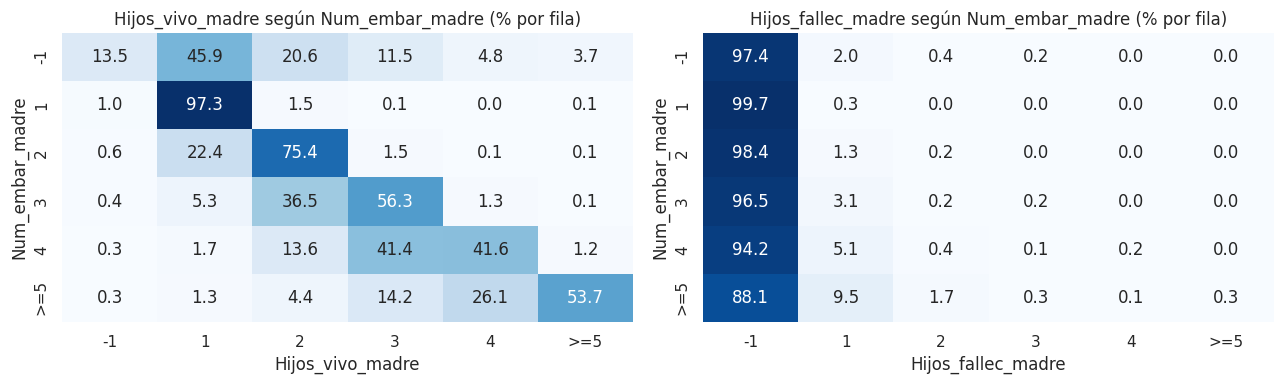

In [ ]:
orden = ["-1", "1", "2", "3", "4", ">=5"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["Hijos_vivo_madre", "Hijos_fallec_madre"]):
    ct = pd.crosstab(df["Num_embar_madre"], df[col], normalize="index").reindex(index=orden, columns=orden) * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{col} según Num_embar_madre (% por fila)")
guardar("semantica_menos1")

**Interpretación.** El diccionario de datos define las tres variables como conteos con valores `-1 (ignorado), 1, 2, 3, 4, >=5`: **ninguna tiene la opción 0**. Además, describe `Num_embar_madre` como el número de embarazos "previos".

- **`Num_embar_madre` incluye el embarazo actual, contra lo que indica el diccionario.** Si contara solo embarazos previos, las madres primerizas no tendrían un valor válido, porque no existe el 0, y deberían figurar como `-1`. Sin embargo, `-1` aparece solo en el 1.0% de los registros (sección 4.1), mientras que el valor 1 agrupa al 30%. Las primerizas, por tanto, están registradas como 1. Por la misma razón, `Hijos_vivo_madre` incluye al recién nacido, lo que explica la diagonal dominante del gráfico izquierdo.
- **En `Num_embar_madre` y `Hijos_vivo_madre`, `-1` es faltante:** es poco frecuente (1.0% y 0.8%) y tiende a aparecer en ambas variables a la vez, como ocurre cuando el campo se deja en blanco.
- **En `Hijos_fallec_madre`, el significado de `-1` es ambiguo.** Aparece en el 97% de los registros y en el 99.7% de las primigestas, que no pueden tener hijos fallecidos previos, lo que sugiere que la mayoría de esos valores significa "ninguno". Pero no hay forma de distinguir, dentro de ese 97%, a las madres sin hijos fallecidos de aquellas cuyo dato no se registró.

**Decisión:** `Hijos_fallec_madre` se excluye. Recodificar `-1` a 0 asumiría un valor que no puede verificarse, y reconstruirlo con la identidad acumularía los errores de tres variables. En `Num_embar_madre` y `Hijos_vivo_madre`, `-1` pasa a `NaN`.

### 4.3 Valores fuera de rango en variables numéricas

In [ ]:
def cat_a_num(s, mapa=None):
    """Convierte una columna 'category' a número trabajando sobre sus categorías (rápido en 4.9 M filas)."""
    cats = pd.Series(s.cat.categories.astype(str).str.strip())
    if mapa:
        cats = cats.replace(mapa)
    vals = pd.to_numeric(cats, errors="coerce").to_numpy(dtype=float)
    codes = s.cat.codes.to_numpy()
    out = np.where(codes >= 0, vals[codes], np.nan)
    return pd.Series(out, index=s.index)

num_raw = pd.DataFrame({c: cat_a_num(df[c]) for c in ["PESO_NACIDO", "TALLA_NACIDO", "DUR_EMB_PARTO", "Edad_Madre"]})
display(num_raw.describe(percentiles=[.001, .01, .5, .99, .999]).T)

RANGOS = {"PESO_NACIDO": (500, 6000), "TALLA_NACIDO": (20, 65), "DUR_EMB_PARTO": (20, 45), "Edad_Madre": (10, 55)}
fuera_rango = pd.DataFrame({
    c: {"rango_valido": f"{lo}–{hi}", "fuera_de_rango": int(((num_raw[c] < lo) | (num_raw[c] > hi)).sum())}
    for c, (lo, hi) in RANGOS.items()}).T
fuera_rango["pct"] = fuera_rango["fuera_de_rango"].astype(int) / len(df) * 100
display(fuera_rango)

for c, (lo, hi) in RANGOS.items():
    x = num_raw[c]
    print(f"\n{c} — valores por debajo de {lo}:", x[x < lo].value_counts().sort_index().head(12).to_dict())
    print(f"{c} — valores por encima de {hi}:", x[x > hi].value_counts().sort_index().tail(12).to_dict())

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
PESO_NACIDO,"4,874,510.000","3,248.093",528.733,-1.000,610.000,"1,552.000","3,270.000","4,400.000","4,887.000","8,000.000"
TALLA_NACIDO,"4,874,510.000",49.103,5.488,-1.000,25.000,39.500,49.500,54.000,56.000,"5,334.000"
DUR_EMB_PARTO,"4,874,510.000",38.620,1.721,3.000,25.000,32.000,39.000,41.000,42.000,99.000
Edad_Madre,"4,874,510.000",28.298,6.938,0.000,14.000,16.000,28.000,43.000,47.000,62.000


,rango_valido,fuera_de_rango,pct
PESO_NACIDO,500–6000,3024,0.062
TALLA_NACIDO,20–65,4729,0.097
DUR_EMB_PARTO,20–45,20,0.000
Edad_Madre,10–55,102,0.002



PESO_NACIDO — valores por debajo de 500: {-1.0: 1315, 30.0: 1, 100.0: 1, 300.0: 558, 301.0: 1, 302.0: 3, 303.0: 2, 304.0: 5, 305.0: 8, 306.0: 1, 307.0: 3, 308.0: 2}
PESO_NACIDO — valores por encima de 6000: {6400.0: 2, 6420.0: 1, 6460.0: 1, 6495.0: 1, 6510.0: 1, 6556.0: 1, 6590.0: 1, 6970.0: 1, 7000.0: 1, 7003.0: 1, 7010.0: 1, 8000.0: 2}

TALLA_NACIDO — valores por debajo de 20: {-1.0: 4697}
TALLA_NACIDO — valores por encima de 65: {80.0: 4, 80.4: 1, 81.0: 1, 82.0: 2, 84.6: 1, 88.5: 1, 92.0: 1, 99.0: 1, 4905.0: 1, 5046.0: 1, 5250.0: 1, 5334.0: 1}

DUR_EMB_PARTO — valores por debajo de 20: {3.0: 1}
DUR_EMB_PARTO — valores por encima de 45: {99.0: 19}

Edad_Madre — valores por debajo de 10: {0.0: 30, 1.0: 3, 2.0: 5, 3.0: 4, 4.0: 4, 5.0: 2, 7.0: 1, 8.0: 2, 9.0: 4}
Edad_Madre — valores por encima de 55: {56.0: 19, 57.0: 8, 58.0: 7, 59.0: 7, 60.0: 5, 62.0: 1}


**Interpretación.** Los rangos se eligieron mirando dónde se cortan las distribuciones, que se ven en las listas de valores extremos:
- **`PESO_NACIDO`:** por debajo de 500 g aparecen el código `-1` (1315 registros) y un grupo anómalo de 558 registros con exactamente 300 g, más varios entre 301 y 308 g. Es probable que sean errores de digitación, por ejemplo 3000 g sin un cero, aunque no se puede confirmar. Por encima de 6000 g hay valores aislados de hasta 8000 g. En total quedan fuera 3024 registros (0.06%).
- **`TALLA_NACIDO`:** el código `-1` aparece 4697 veces, hay tallas de 80 a 99 cm y valores como 4905 o 5334, que parecen tallas de 49.05 o 53.34 cm sin el punto decimal. No se usa como feature.
- **`DUR_EMB_PARTO`:** hay un registro con 3 semanas y 19 con 99, aislados del rango 20–43.
- **`Edad_Madre`:** hay 55 registros con edades de 0 a 9 años, imposibles, y 47 entre 56 y 62 años, extremadamente improbables.

**Decisión:** menos del 0.1% de los registros queda fuera de rango. Esos valores pasan a `NaN`, y los registros sin peso válido se eliminan en el preprocesamiento porque no tienen target.

### 4.4 Duplicados

In [ ]:
dup = df.duplicated(keep=False)
print(f"Filas idénticas en las 22 columnas: {df.duplicated().sum():,} ({df.duplicated().mean()*100:.3f}%)")
print("\nTipo_Parto entre los registros duplicados (proporción):")
print(df.loc[dup, "Tipo_Parto"].value_counts(normalize=True).round(3).head().to_string())

Filas idénticas en las 22 columnas: 974 (0.020%)

Tipo_Parto entre los registros duplicados (proporción):
Tipo_Parto
UNICO         0.909
DOBLE         0.084
TRIPLE        0.008
MAS DE TRES   0.000
IGNORADO      0.000


**Interpretación.** Hay 974 filas idénticas (0.02%). El dataset no tiene un identificador único, así que no es posible distinguir un error de registro de dos nacimientos distintos con los mismos atributos. El 8.4% de estos duplicados son partos dobles, lo que sugiere que al menos parte son nacimientos reales.

**Decisión:** se mantienen. Su efecto sobre el análisis es despreciable y eliminarlos podría borrar nacimientos legítimos.

### 4.5 Consistencia entre variables

Se verifican combinaciones que no deberían ocurrir: más hijos vivos que embarazos, y madres muy jóvenes con muchos embarazos.

In [ ]:
ne = cat_a_num(df["Num_embar_madre"], {">=5": "5", "-1": "nan"})
hv = cat_a_num(df["Hijos_vivo_madre"], {">=5": "5", "-1": "nan"})
inc = (hv > ne) & (ne < 5)          # con ">=5" no se puede comparar
print(f"Registros con Hijos_vivo_madre > Num_embar_madre: {inc.sum():,} ({inc.mean()*100:.2f}%)")
print("Tipo_Parto en esos registros (proporción):")
print(df.loc[inc, "Tipo_Parto"].value_counts(normalize=True).round(3).to_string())
inc_unico = inc & (df["Tipo_Parto"] == "UNICO")
print(f"→ inconsistentes y con parto único (no explicables por gemelos): {inc_unico.sum():,} ({inc_unico.mean()*100:.2f}%)")

joven = (num_raw["Edad_Madre"] <= 15) & (ne >= 4)
print(f"\nMadres de 15 años o menos con 4 o más embarazos: {joven.sum():,}")

Registros con Hijos_vivo_madre > Num_embar_madre: 67,291 (1.38%)
Tipo_Parto en esos registros (proporción):
Tipo_Parto
DOBLE         0.549
UNICO         0.437
TRIPLE        0.013
IGNORADO      0.001
MAS DE TRES   0.000
→ inconsistentes y con parto único (no explicables por gemelos): 29,392 (0.60%)

Madres de 15 años o menos con 4 o más embarazos: 106


**Interpretación.**
- **Más hijos vivos que embarazos:** hay 67 291 registros (1.38%) en esta situación. El 55% corresponde a partos dobles, donde es esperable: una primigesta con gemelos tiene un embarazo y dos hijos vivos. Pero **29 392 registros (0.60%) son partos únicos**, y en ellos la combinación es imposible. Al menos uno de los dos campos está mal registrado, y no se puede saber cuál.
- **Madres muy jóvenes con muchos embarazos:** hay 106 madres de 15 años o menos con cuatro o más embarazos. Es improbable pero no imposible.

**Decisión:** se mantienen ambos grupos. El impacto es menor al 0.7% y no hay forma de corregirlos. Sin embargo, el registro tiene errores también en la historia obstétrica, y esto se reporta como limitación.

### 4.6 Consistencia de registro: `Estado_Civil`

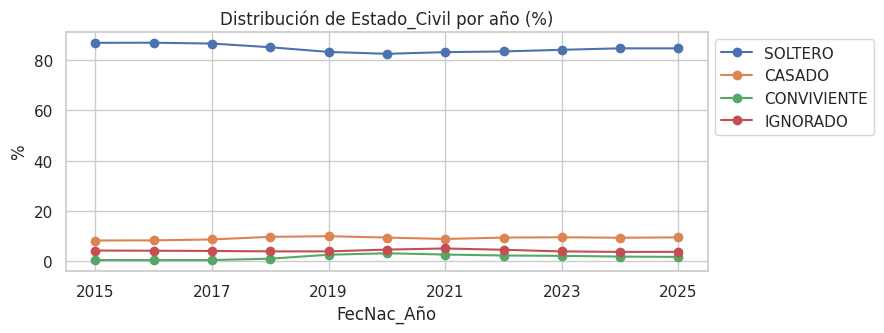

Estado_Civil,CASADO,CONVIVIENTE,DIVORCIADO,IGNORADO,SOLTERO,VIUDO,SEPARADO
FecNac_Año,,,,,,,
2015,8.200,0.400,0.300,4.200,86.800,0.000,0.000
2016,8.200,0.400,0.300,4.100,86.900,0.000,0.000
2017,8.600,0.400,0.300,4.000,86.500,0.000,0.000
2018,9.700,1.000,0.400,3.900,85.100,0.000,0.000
2019,9.900,2.500,0.400,3.900,83.200,0.000,0.000
2020,9.400,3.100,0.400,4.600,82.500,0.000,0.000
2021,8.800,2.600,0.400,5.000,83.100,0.000,0.000
2022,9.400,2.200,0.400,4.500,83.400,0.000,0.000
2023,9.500,2.100,0.500,3.900,84.100,0.000,0.000


Estado_Civil según grupo de edad de la madre (% por fila):


Estado_Civil,CASADO,CONVIVIENTE,DIVORCIADO,IGNORADO,SOLTERO,VIUDO,SEPARADO
Edad_Madre,,,,,,,
≤17,0.100,1.200,0.000,78.700,20.100,0.000,0.000
18–24,1.200,2.400,0.000,1.900,94.500,0.000,0.000
25–34,10.100,1.700,0.300,0.000,87.900,0.000,0.000
≥35,19.700,0.800,1.200,0.000,78.200,0.100,0.000


In [ ]:
ec = pd.crosstab(df["FecNac_Año"], df["Estado_Civil"], normalize="index") * 100
ax = ec[["SOLTERO", "CASADO", "CONVIVIENTE", "IGNORADO"]].plot(figsize=(9, 3.5), marker="o")
ax.set_title("Distribución de Estado_Civil por año (%)"); ax.set_ylabel("%"); ax.legend(bbox_to_anchor=(1, 1))
guardar("estado_civil_por_anio")
display(ec.round(1))

grupo_tmp = pd.cut(num_raw["Edad_Madre"], [9, 17, 24, 34, 55], labels=["≤17", "18–24", "25–34", "≥35"])
print("Estado_Civil según grupo de edad de la madre (% por fila):")
display((pd.crosstab(grupo_tmp, df["Estado_Civil"], normalize="index") * 100).round(1))

**Interpretación.**
- Entre 83% y 87% de las madres figuran como "soltera" en todos los años, y solo entre 0.4% y 3.1% como "conviviente". La categoría "conviviente" sube de 0.4% a 3.1% entre 2017 y 2020 sin un cambio equivalente en otras categorías, lo que apunta a un cambio en la forma de registro y no a un cambio demográfico.
- La tabla por edad muestra el problema más grave: **el 78.7% de las madres de 17 años o menos tiene `Estado_Civil = IGNORADO`**, frente a 0% en las mayores de 25. El faltante depende de la edad, que es justamente un factor de riesgo (sección 7). Eliminar los casos incompletos de esta variable eliminaría a la mayoría de las madres adolescentes.

**Decisión:** `Estado_Civil` se excluye de ambos escenarios por tres razones:
1. **Baja validez:** la distribución (≈ 85% "soltero") y el salto de "conviviente" entre 2017 y 2020 indican que la variable refleja la práctica de registro más que el estado civil real.
2. **Faltante dependiente de la edad:** el 78.7% de las madres de 17 años o menos no tiene el dato. Eliminar esos casos excluiría a la mayoría de un grupo de alto riesgo (sección 7), y agruparlos en "desconocido" haría que la variable funcione como un indicador indirecto de la edad.
3. **Precedente con el mismo dataset:** Andrade-Girón et al. (2026), que trabajan con el CNV, tampoco la incluyen entre sus predictores. Almeida et al. (2026) sí la usan, pero con datos del SINASC, donde la variable no presenta estos problemas. Esta diferencia se reporta como limitación frente al paper de referencia.

### 4.7 Limpieza mínima para el análisis exploratorio

Se crea `df_eda`, una copia limpia **solo para que los gráficos sean correctos**. No incluye codificación, escalado ni imputación: eso se hace en `src/preprocessing.py` después del split train/test. Reglas aplicadas, todas justificadas en las secciones 4.1 a 4.3:

- `IGNORADO` pasa a `NaN` en todas las variables categóricas.
- `-1` pasa a `NaN` en `Num_embar_madre`, `Hijos_vivo_madre` e `IdUbigeoInei`.
- `Hijos_fallec_madre` no se incluye en `df_eda` (ver 4.2).
- `NINGUNO` pasa a `0` y `IGNORADO` a `NaN` en `nacmuer_abort_madre`; `>=5` se trata como 5 y `11 a más` como 11.
- Los valores fuera de los rangos de la sección 4.3 pasan a `NaN`.
- `departamento` se deriva de los dos primeros dígitos del ubigeo de residencia de la madre.
- `pais_grupo` agrupa `Pais_Madre` en Perú, Venezuela y Otro, porque los demás países tienen muy pocos registros (ver sección 3).

In [ ]:
DEPARTAMENTOS = {
    "01": "Amazonas", "02": "Áncash", "03": "Apurímac", "04": "Arequipa", "05": "Ayacucho",
    "06": "Cajamarca", "07": "Callao", "08": "Cusco", "09": "Huancavelica", "10": "Huánuco",
    "11": "Ica", "12": "Junín", "13": "La Libertad", "14": "Lambayeque", "15": "Lima",
    "16": "Loreto", "17": "Madre de Dios", "18": "Moquegua", "19": "Pasco", "20": "Piura",
    "21": "Puno", "22": "San Martín", "23": "Tacna", "24": "Tumbes", "25": "Ucayali"}

def limpiar_cat(s, nulos=("IGNORADO",), mapa=None):
    d = {}
    for c in s.cat.categories:
        v = str(c).strip()
        v = (mapa or {}).get(v, v)
        d[c] = np.nan if v in nulos else v
    return s.map(d).astype("category")

df_eda = pd.DataFrame(index=df.index)

for c, (lo, hi) in RANGOS.items():
    x = num_raw[c]
    df_eda[c] = x.where(x.between(lo, hi))

for c in ["Tipo_Parto", "Estado_Civil", "Financiador_Parto", "sexo_nacido"]:
    df_eda[c] = limpiar_cat(df[c])
df_eda["Nivel_Instruccion"] = limpiar_cat(df["Nivel_Intrucción_Madre"],
                                          mapa={"INCIAL/PRE-ESCOLAR": "INICIAL/PRE-ESCOLAR"})

df_eda["Num_embar_madre"]     = cat_a_num(df["Num_embar_madre"],    {">=5": "5", "-1": "nan"})
df_eda["Hijos_vivo_madre"]    = cat_a_num(df["Hijos_vivo_madre"],   {">=5": "5", "-1": "nan"})
df_eda["nacmuer_abort_madre"] = cat_a_num(df["nacmuer_abort_madre"],
                                          {"NINGUNO": "0", "IGNORADO": "nan", "11 a más": "11"})

ubi = df["IdUbigeoInei"].astype(str).str.strip()
df_eda["departamento"] = ubi.where(ubi != "-1").str.zfill(6).str[:2].map(DEPARTAMENTOS).astype("category")
pais = df["Pais_Madre"].astype(str).str.strip()
df_eda["pais_grupo"] = pais.where(pais.isin(["PERU", "VENEZUELA"]), "OTRO").astype("category")
df_eda["anio"] = df["FecNac_Año"].astype(int)

df_eda["bajo_peso"] = np.where(df_eda["PESO_NACIDO"].isna(), np.nan, (df_eda["PESO_NACIDO"] < 2500).astype(float))

faltantes_eda = (df_eda.isna().mean() * 100).sort_values(ascending=False)
print("% de faltantes tras la limpieza mínima:")
print(faltantes_eda.round(2).to_string())

FEATS_A = ["Edad_Madre", "Nivel_Instruccion", "Financiador_Parto", "Tipo_Parto", "sexo_nacido", "departamento", "pais_grupo",
           "Num_embar_madre", "nacmuer_abort_madre"]
cc_todo = df_eda[FEATS_A + ["bajo_peso"]].notna().all(axis=1).mean()
cc_sin_abort = df_eda[[f for f in FEATS_A if f != "nacmuer_abort_madre"] + ["bajo_peso"]].notna().all(axis=1).mean()
print(f"\nRegistros completos en todas las features del Escenario A: {cc_todo*100:.1f}%")
print(f"Ídem, sin contar nacmuer_abort_madre:                     {cc_sin_abort*100:.1f}%")

falta_ab = df_eda["nacmuer_abort_madre"].isna()
print(f"\nBajo peso cuando nacmuer_abort_madre falta: {df_eda.loc[falta_ab, 'bajo_peso'].mean()*100:.2f}%"
      f"  |  cuando está presente: {df_eda.loc[~falta_ab, 'bajo_peso'].mean()*100:.2f}%")

% de faltantes tras la limpieza mínima:
nacmuer_abort_madre   8.570
Estado_Civil          4.150
Num_embar_madre       1.020
Financiador_Parto     0.790
Hijos_vivo_madre      0.770
departamento          0.180
Tipo_Parto            0.170
TALLA_NACIDO          0.100
bajo_peso             0.060
PESO_NACIDO           0.060
Nivel_Instruccion     0.050
sexo_nacido           0.000
Edad_Madre            0.000
DUR_EMB_PARTO         0.000
pais_grupo            0.000
anio                  0.000

Registros completos en todas las features del Escenario A: 89.5%
Ídem, sin contar nacmuer_abort_madre:                     97.8%

Bajo peso cuando nacmuer_abort_madre falta: 6.60%  |  cuando está presente: 6.36%


**Interpretación.**
- Tras la limpieza, el único faltante relevante entre las features es `nacmuer_abort_madre` (8.6%).
- Con un análisis de casos completos se conserva el 89.5% de los registros; sin esa variable, el 97.8%.
- La tasa de bajo peso es casi igual cuando el antecedente de abortos falta (6.60%) que cuando está presente (6.36%). Es decir, el faltante no está asociado al target y eliminar esas filas no introduce un sesgo apreciable.

**Decisión:** se aplica **eliminación de casos completos**, el mismo criterio que usa el paper de referencia (Almeida et al. (2026), con datos del SINASC de Brasil) para los valores ignorados. Con más de 4.3 millones de registros restantes, la pérdida de tamaño muestral no es un problema.

*La lista de features usada aquí corresponde a la versión final del Escenario A: incluye `pais_grupo`, cuya relevancia se demuestra en la sección 7, y excluye `Estado_Civil` (4.6), `Hijos_fallec_madre` (4.2) y `Hijos_vivo_madre` (8).*

## 5. Análisis del target

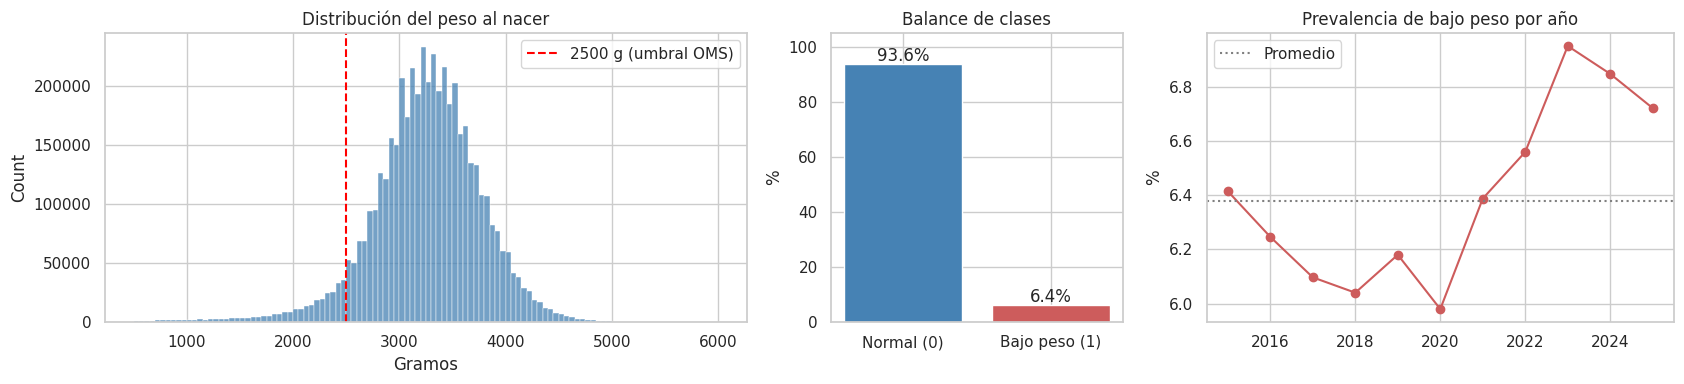

Prevalencia global de bajo peso: 6.38%  |  Ratio de desbalance ≈ 1:15
count   4,871,486.000
mean        3,249.900
std           523.400
min           500.000
25%         2,970.000
50%         3,274.000
75%         3,580.000
max         6,000.000

Prevalencia por año (%):
anio
2015   6.410
2016   6.250
2017   6.100
2018   6.040
2019   6.180
2020   5.980
2021   6.390
2022   6.560
2023   6.950
2024   6.850
2025   6.720


In [ ]:
prev = df_eda["bajo_peso"].mean()
fig, axes = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={"width_ratios": [2.2, 1, 1.6]})

sns.histplot(df_eda["PESO_NACIDO"].dropna(), binwidth=50, ax=axes[0], color="steelblue")
axes[0].axvline(2500, color="red", ls="--", label="2500 g (umbral OMS)")
axes[0].set_title("Distribución del peso al nacer"); axes[0].set_xlabel("Gramos"); axes[0].legend()

vc = df_eda["bajo_peso"].value_counts(normalize=True).sort_index() * 100
axes[1].bar(["Normal (0)", "Bajo peso (1)"], vc.values, color=["steelblue", "indianred"])
for i, v in enumerate(vc.values):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
axes[1].set_title("Balance de clases"); axes[1].set_ylabel("%"); axes[1].set_ylim(0, 105)

tend = df_eda.groupby("anio")["bajo_peso"].mean() * 100
axes[2].plot(tend.index, tend.values, marker="o", color="indianred")
axes[2].axhline(prev * 100, color="gray", ls=":", label="Promedio")
axes[2].set_title("Prevalencia de bajo peso por año"); axes[2].set_ylabel("%"); axes[2].legend()
guardar("target")

print(f"Prevalencia global de bajo peso: {prev*100:.2f}%  |  Ratio de desbalance ≈ 1:{(1-prev)/prev:.0f}")
print(df_eda["PESO_NACIDO"].describe().round(1).to_string())
print("\nPrevalencia por año (%):"); print(tend.round(2).to_string())

In [ ]:
# Redondeo de dígitos (heaping): ¿el peso se registra redondeado?
p = df_eda["PESO_NACIDO"].dropna()
print(f"Pesos múltiplos de 100 g: {(p % 100 == 0).mean()*100:.1f}%  (sin redondeo se esperaría ~1%)")
print(f"Pesos múltiplos de 50 g:  {(p % 50 == 0).mean()*100:.1f}%  (sin redondeo se esperaría ~2%)")
print("\nFrecuencia de valores alrededor del umbral:")
print(p.value_counts().reindex([2450, 2480, 2490, 2495, 2500, 2505, 2510, 2520, 2550]).to_string())

Pesos múltiplos de 100 g: 15.7%  (sin redondeo se esperaría ~1%)
Pesos múltiplos de 50 g:  24.7%  (sin redondeo se esperaría ~2%)

Frecuencia de valores alrededor del umbral:
PESO_NACIDO
2450     6161
2480     5223
2490     4679
2495     1328
2500    16353
2505     1515
2510     5657
2520     6256
2550     8937


**Interpretación.**
- **Distribución:** el peso tiene media de 3250 g y desviación estándar de 523 g, con una cola izquierda larga. La sección 9 muestra que esa cola corresponde principalmente a los partos prematuros.
- **Desbalance:** la prevalencia de bajo peso es **6.38%**, una proporción de 1:15. Un modelo que prediga siempre "peso normal" tendría 93.6% de accuracy sin detectar un solo caso.

  **Decisión:** split estratificado por `bajo_peso`, ponderación de clases o técnicas de balanceo, y evaluación con recall, F1 y AUC-ROC.
- **Tendencia temporal:** la prevalencia bajó de 6.4% (2015) a 6.0% (2020) y luego subió a 6.9% (2023). La diferencia es de casi un punto porcentual.

  **Decisión:** se usa un split aleatorio estratificado. Como prueba de robustez opcional, puede entrenarse con 2015–2023 y evaluar con 2024–2025.
- **Redondeo de dígitos (heaping):** el 15.7% de los pesos son múltiplos de 100 g, frente al ~1% esperable. Hay 16 353 registros con exactamente 2500 g, frente a 4679 con 2490 g. **Hipótesis (no verificable con estos datos):** parte de los recién nacidos que pesaron un poco menos de 2500 g se registró como 2500 g y quedó clasificada como peso normal. Si fuera así, habría ruido en la etiqueta justo en el umbral.

  **Decisión:** se mantiene el umbral estándar de la OMS (< 2500 g) y el redondeo se reporta como limitación.

## 6. Análisis univariado de las features

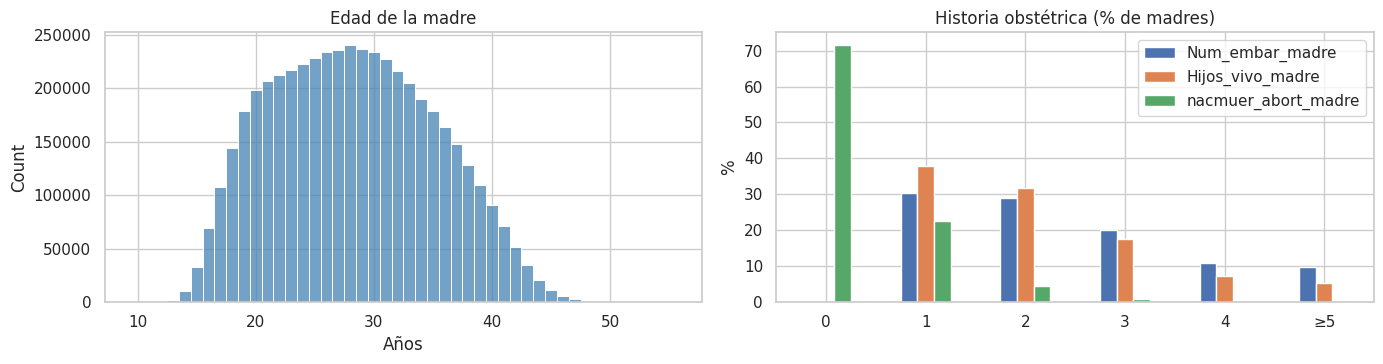

count   4,874,408.000
mean           28.300
std             6.900
min            10.000
25%            23.000
50%            28.000
75%            33.000
max            55.000
Madres ≤17 años: 4.6%  |  ≥35 años: 21.0%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.histplot(df_eda["Edad_Madre"].dropna(), discrete=True, ax=axes[0], color="steelblue")
axes[0].set_title("Edad de la madre"); axes[0].set_xlabel("Años")

paridad = ["Num_embar_madre", "Hijos_vivo_madre", "nacmuer_abort_madre"]
dist_par = pd.DataFrame({c: df_eda[c].clip(upper=5).value_counts(normalize=True).sort_index() * 100 for c in paridad})
dist_par.index = [f"{int(i)}" if i < 5 else "≥5" for i in dist_par.index]
dist_par.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Historia obstétrica (% de madres)"); axes[1].set_ylabel("%")
guardar("univariado_numericas")

print(df_eda["Edad_Madre"].describe().round(1).to_string())
print(f"Madres ≤17 años: {(df_eda['Edad_Madre'] <= 17).mean()*100:.1f}%  |  ≥35 años: {(df_eda['Edad_Madre'] >= 35).mean()*100:.1f}%")

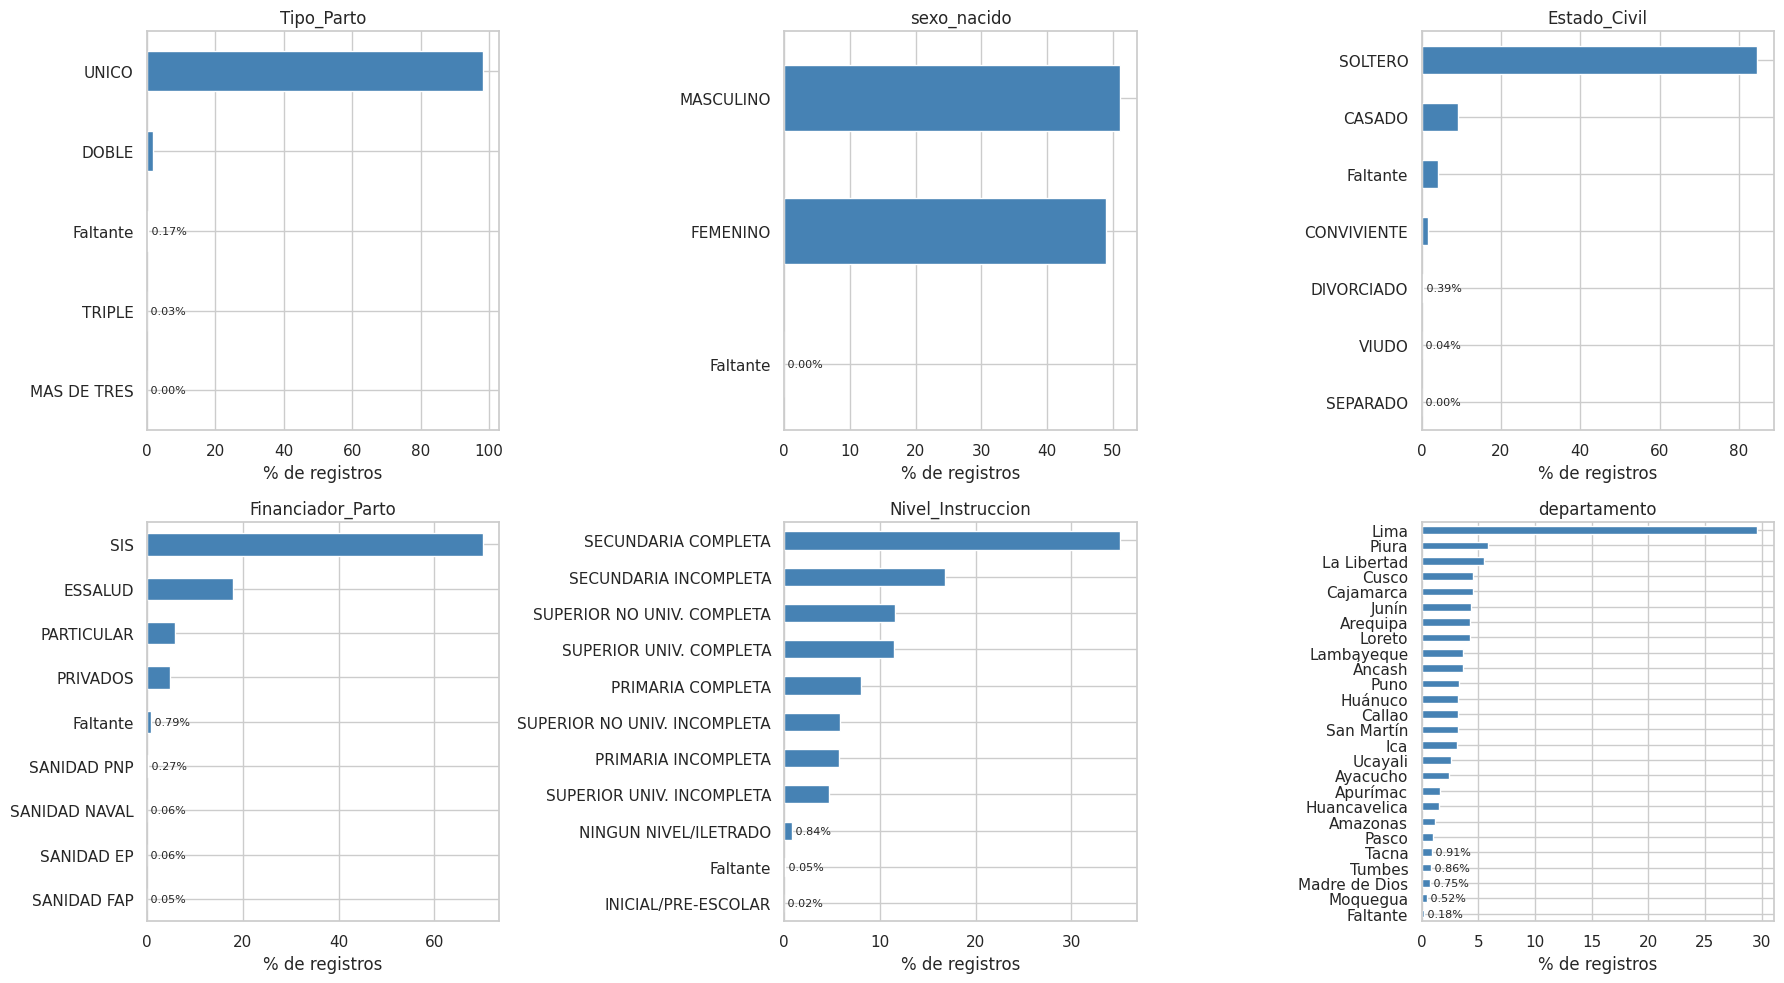

In [ ]:
cat_cols = ["Tipo_Parto", "sexo_nacido", "Estado_Civil", "Financiador_Parto", "Nivel_Instruccion", "departamento"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes.flat, cat_cols):
    vc = df_eda[c].value_counts(normalize=True, dropna=False).sort_values() * 100
    vc.index = ["Faltante" if pd.isna(i) else str(i) for i in vc.index]
    vc.plot.barh(ax=ax, color="steelblue")
    ax.set_title(c); ax.set_xlabel("% de registros")
    for i, v in enumerate(vc.values):
        if v < 1:
            ax.text(v, i, f" {v:.2f}%", va="center", fontsize=8)
guardar("univariado_categoricas")

In [ ]:
for c in cat_cols + ["pais_grupo"]:
    vc = df_eda[c].value_counts(dropna=False)
    t = pd.DataFrame({"n": vc, "pct": vc / len(df_eda) * 100})
    t.index = ["Faltante" if pd.isna(i) else str(i) for i in t.index]
    print(f"\n{c}:"); print(t.round(2).to_string())


Tipo_Parto:
                   n    pct
UNICO        4781890 98.100
DOBLE          82682  1.700
Faltante        8374  0.170
TRIPLE          1486  0.030
MAS DE TRES       78  0.000

sexo_nacido:
                 n    pct
MASCULINO  2490143 51.080
FEMENINO   2384174 48.910
Faltante       193  0.000

Estado_Civil:
                   n    pct
SOLTERO      4124661 84.620
CASADO        445017  9.130
Faltante      202327  4.150
CONVIVIENTE    81154  1.660
DIVORCIADO     19164  0.390
VIUDO           2114  0.040
SEPARADO          73  0.000

Financiador_Parto:
                     n    pct
SIS            3416656 70.090
ESSALUD         876584 17.980
PARTICULAR      284196  5.830
PRIVADOS        236672  4.860
Faltante         38679  0.790
SANIDAD PNP      13329  0.270
SANIDAD NAVAL     3108  0.060
SANIDAD EP        2682  0.060
SANIDAD FAP       2604  0.050

Nivel_Instruccion:
                                    n    pct
SECUNDARIA COMPLETA           1710409 35.090
SECUNDARIA INCOMPLETA          8

**Interpretación** (los números salen de la tabla de conteos de la celda anterior):
- **Edad materna:** la media es 28.3 años. El 4.6% de las madres tiene 17 años o menos y el 21% tiene 35 o más.
- **Historia obstétrica:** la mayoría de madres está en su primer o segundo embarazo. Los abortos se concentran en 0, así que esa variable tiene poca varianza.
- **Categorías raras que hay que agrupar:**
  - `Tipo_Parto`: "TRIPLE" (1486) y "MAS DE TRES" (78) se unen con "DOBLE" (82 682) en "MÚLTIPLE".
  - `Financiador_Parto`: las cuatro sanidades (entre 2604 y 13 329 registros cada una) se agrupan en "SANIDAD FF.AA./PNP".
  - `Nivel_Instruccion`: "INICIAL/PRE-ESCOLAR" (871) se une con "NINGÚN NIVEL/ILETRADO" (40 957).
  - `pais_grupo`: Venezuela representa el 2.1% y el resto de países el 0.4%.
- **Concentración:** el SIS financia el 70.1% de los partos y Lima concentra el 29.6% de los registros. El modelo verá muchos más ejemplos de estos grupos que del resto.

## 7. Análisis bivariado: features vs bajo peso

Para cada feature se calcula la **tasa de bajo peso por categoría**. La línea roja marca la prevalencia global; cuanto más se alejan las barras de esa línea, más información aporta la variable. Se omiten las categorías con menos de 300 registros para que no distorsionen la escala.

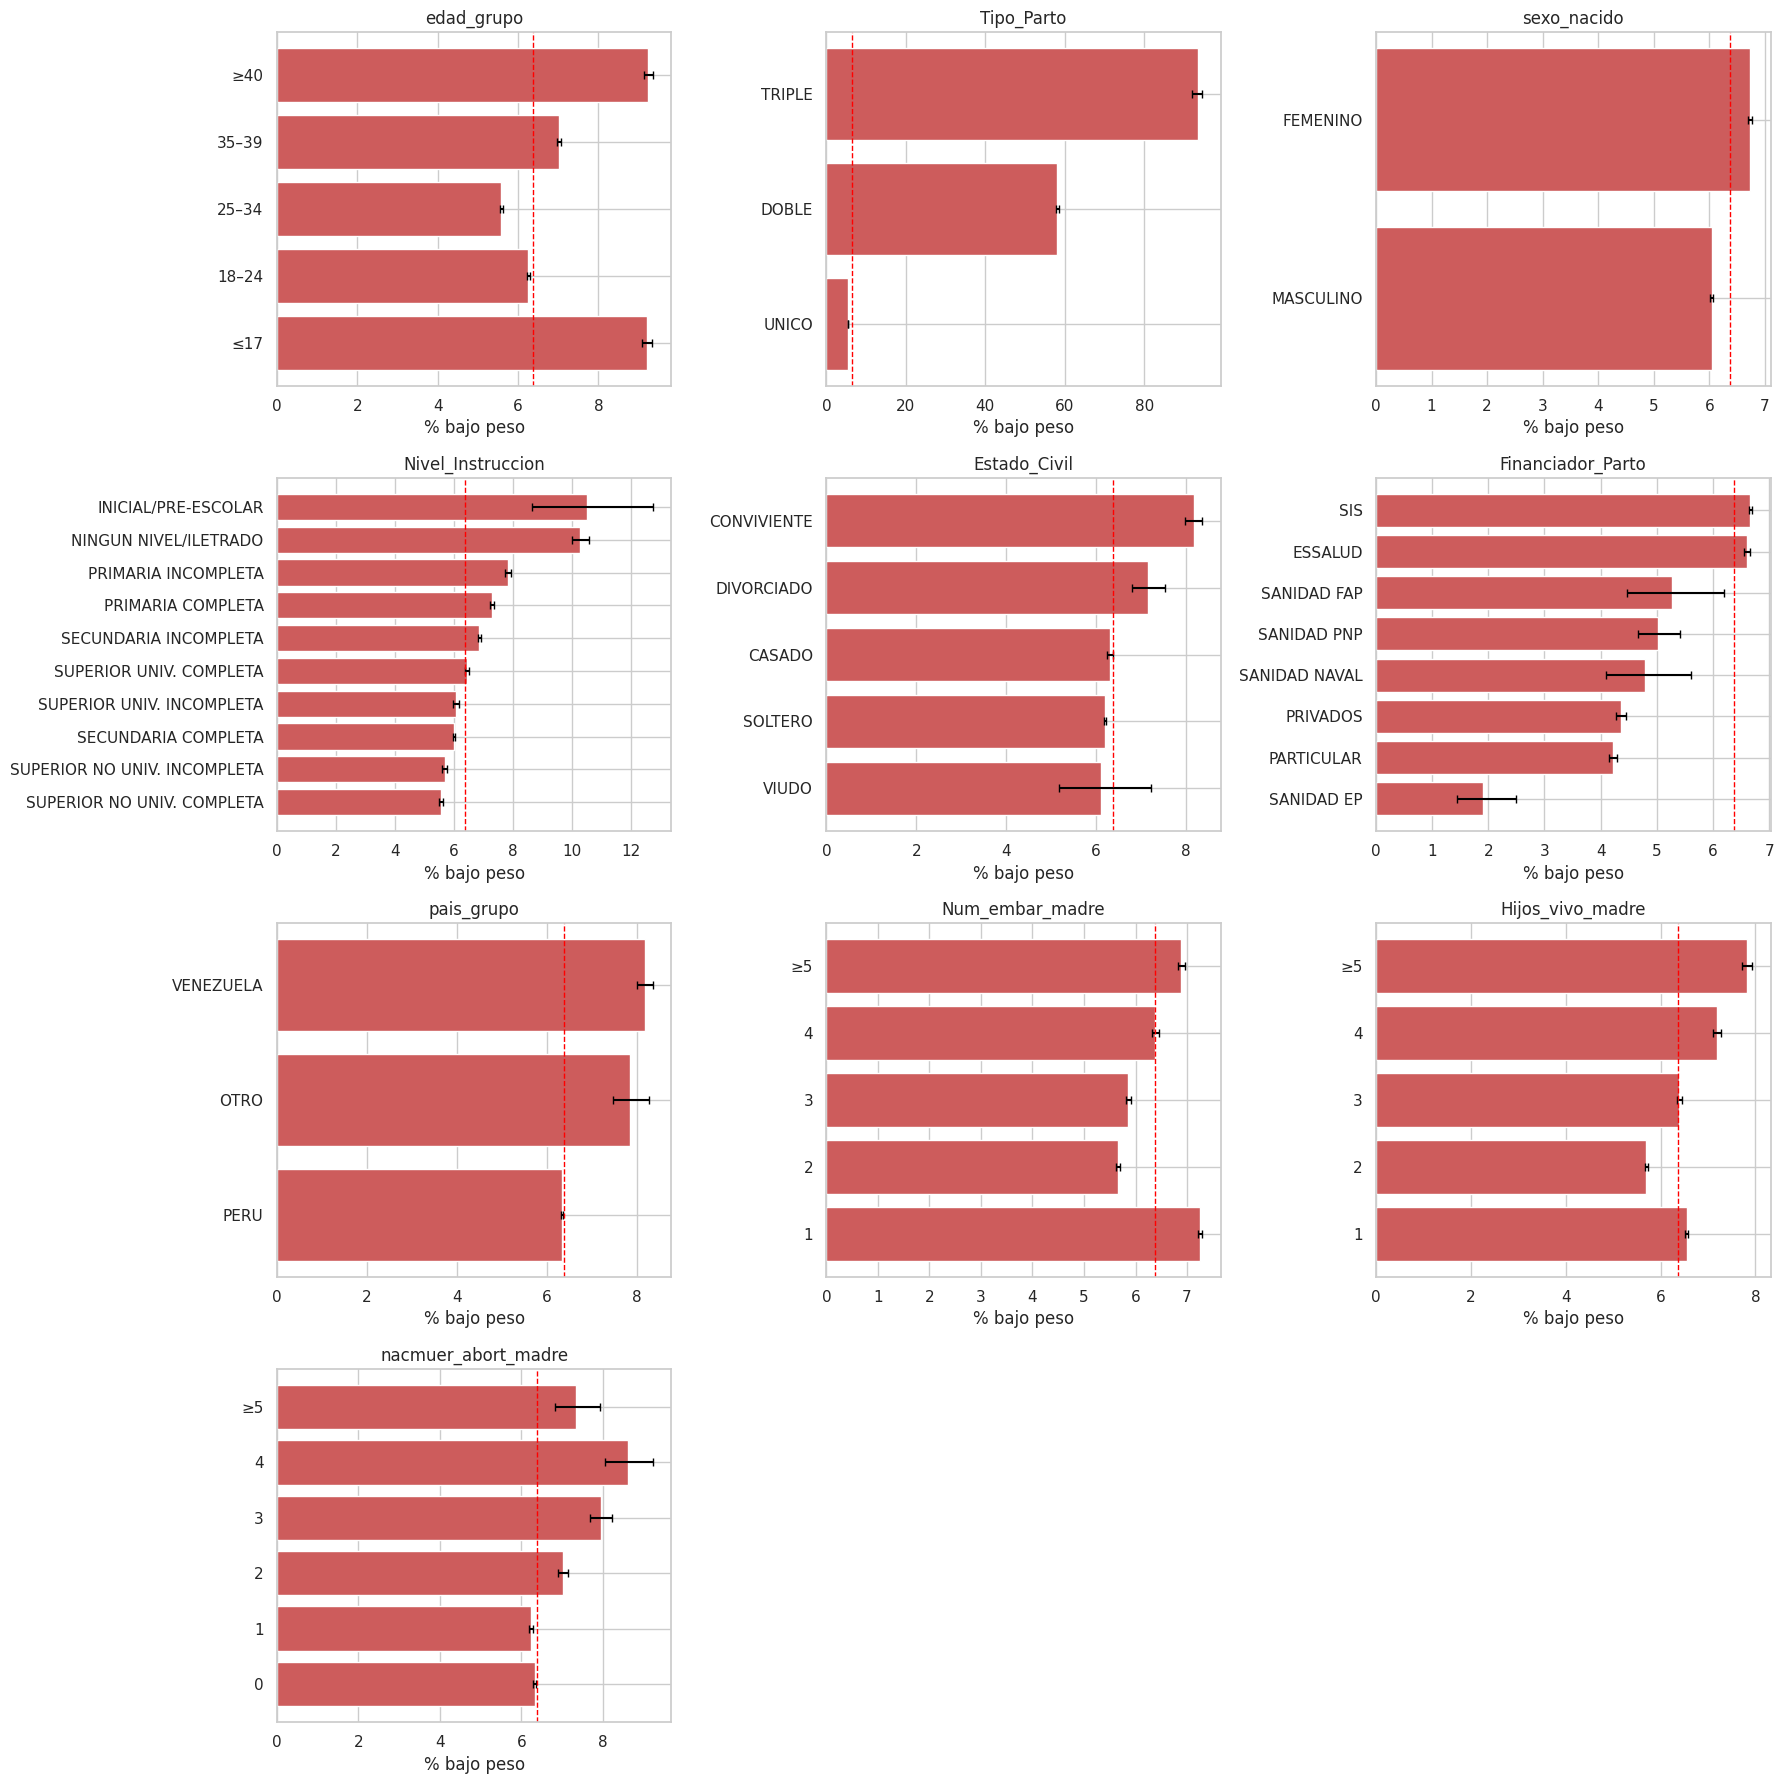


edad_grupo:
            tasa  ic_inf  ic_sup        n
edad_grupo                               
≤17        9.200   9.080   9.320   223510
18–24      6.260   6.220   6.300  1379065
25–34      5.590   5.560   5.620  2247879
35–39      7.020   6.960   7.080   728608
≥40        9.240   9.140   9.350   292328

Tipo_Parto:
             tasa  ic_inf  ic_sup        n
Tipo_Parto                                
DOBLE      58.130  57.790  58.470    82620
TRIPLE     93.440  92.060  94.590     1479
UNICO       5.460   5.440   5.480  4778954

sexo_nacido:
             tasa  ic_inf  ic_sup        n
sexo_nacido                               
FEMENINO    6.730   6.700   6.760  2382685
MASCULINO   6.040   6.010   6.070  2488611

Nivel_Instruccion:
                               tasa  ic_inf  ic_sup        n
Nivel_Instruccion                                           
INICIAL/PRE-ESCOLAR          10.510   8.640  12.730      866
NINGUN NIVEL/ILETRADO        10.270   9.980  10.570    40877
PRIMARIA COMPLE

In [ ]:
df_eda["edad_grupo"] = pd.cut(df_eda["Edad_Madre"], [9, 17, 24, 34, 39, 55],
                              labels=["≤17", "18–24", "25–34", "35–39", "≥40"])
for c in paridad:
    df_eda[c + "_cat"] = pd.Categorical(
        df_eda[c].clip(upper=5).map(lambda v: np.nan if pd.isna(v) else ("≥5" if v >= 5 else str(int(v)))),
        categories=["0", "1", "2", "3", "4", "≥5"], ordered=True)

def tasa(col, min_n=300, z=1.96):
    """Tasa de bajo peso por categoría con intervalo de confianza de Wilson al 95%."""
    t = df_eda.groupby(col, observed=True)["bajo_peso"].agg(p="mean", n="count")
    t = t[t["n"] >= min_n].copy()
    centro = (t["p"] + z**2 / (2 * t["n"])) / (1 + z**2 / t["n"])
    margen = z * np.sqrt(t["p"] * (1 - t["p"]) / t["n"] + z**2 / (4 * t["n"]**2)) / (1 + z**2 / t["n"])
    t["tasa"], t["ic_inf"], t["ic_sup"] = t["p"] * 100, (centro - margen) * 100, (centro + margen) * 100
    return t[["tasa", "ic_inf", "ic_sup", "n"]]

ordenadas = {"edad_grupo"} | {c + "_cat" for c in paridad}
bivar = ["edad_grupo", "Tipo_Parto", "sexo_nacido", "Nivel_Instruccion", "Estado_Civil", "Financiador_Parto",
         "pais_grupo", "Num_embar_madre_cat", "Hijos_vivo_madre_cat", "nacmuer_abort_madre_cat"]
fig, axes = plt.subplots(4, 3, figsize=(18, 18))
tablas = {}
for ax, c in zip(axes.flat, bivar):
    t = tasa(c); tablas[c] = t
    tt = t if c in ordenadas else t.sort_values("tasa")
    err = np.vstack([tt["tasa"] - tt["ic_inf"], tt["ic_sup"] - tt["tasa"]])
    ax.barh(tt.index.astype(str), tt["tasa"], xerr=err, color="indianred", ecolor="black", capsize=3)
    ax.axvline(prev * 100, color="red", ls="--", lw=1)
    ax.set_title(c.replace("_cat", "")); ax.set_xlabel("% bajo peso"); ax.set_ylabel("")
for ax in axes.flat[len(bivar):]:
    ax.axis("off")
guardar("bivariado_tasas")

for c, t in tablas.items():
    print(f"\n{c.replace('_cat', '')}:"); print(t.round(2).to_string())

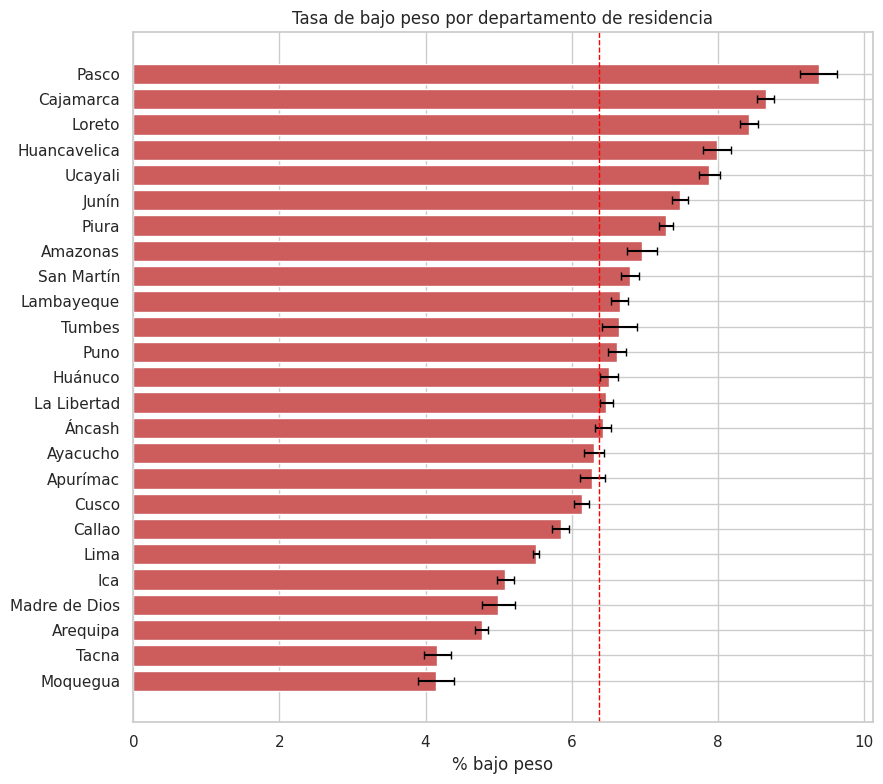

               tasa  ic_inf  ic_sup        n
departamento                                
Pasco         9.380   9.130   9.640    50102
Cajamarca     8.650   8.540   8.770   219435
Loreto        8.430   8.310   8.550   207853
Huancavelica  7.990   7.800   8.180    75257
Ucayali       7.880   7.740   8.030   126380
Junín         7.480   7.370   7.600   210751
Piura         7.290   7.200   7.390   284082
Amazonas      6.960   6.760   7.170    59240
San Martín    6.800   6.670   6.920   156143
Lambayeque    6.660   6.540   6.770   178323
Tumbes        6.650   6.420   6.900    41673
Puno          6.620   6.500   6.740   161008
Huánuco       6.510   6.390   6.640   157502
La Libertad   6.470   6.380   6.570   268675
Áncash        6.430   6.320   6.540   178022
Ayacucho      6.310   6.170   6.450   119057
Apurímac      6.280   6.120   6.460    78226
Cusco         6.140   6.040   6.240   221022
Callao        5.850   5.730   5.970   157087
Lima          5.510   5.470   5.550  1442926
Ica       

In [ ]:
t_dep = tasa("departamento").sort_values("tasa")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(t_dep.index.astype(str), t_dep["tasa"], color="indianred", ecolor="black", capsize=3,
        xerr=np.vstack([t_dep["tasa"] - t_dep["ic_inf"], t_dep["ic_sup"] - t_dep["tasa"]]))
ax.axvline(prev * 100, color="red", ls="--", lw=1)
ax.set_title("Tasa de bajo peso por departamento de residencia"); ax.set_xlabel("% bajo peso"); ax.set_ylabel("")
guardar("bivariado_departamento")
tablas["departamento"] = t_dep
print(t_dep.sort_values("tasa", ascending=False).round(2).to_string())

In [ ]:
# Resumen: brecha entre la categoría de mayor y menor riesgo de cada feature
brecha = pd.DataFrame({
    c.replace("_cat", ""): {"tasa_min_%": t["tasa"].min(), "tasa_max_%": t["tasa"].max(),
                            "categoria_max": t["tasa"].idxmax(),
                            "brecha_pp": t["tasa"].max() - t["tasa"].min(),
                            "riesgo_relativo": t["tasa"].max() / t["tasa"].min()}
    for c, t in tablas.items()}).T.sort_values("brecha_pp", ascending=False)
brecha

,tasa_min_%,tasa_max_%,categoria_max,brecha_pp,riesgo_relativo
Tipo_Parto,5.458,93.442,TRIPLE,87.984,17.121
departamento,4.138,9.379,Pasco,5.241,2.266
Nivel_Instruccion,5.568,10.508,INICIAL/PRE-ESCOLAR,4.941,1.887
Financiador_Parto,1.902,6.662,SIS,4.760,3.502
edad_grupo,5.588,9.242,≥40,3.654,1.654
nacmuer_abort_madre,6.239,8.616,4,2.377,1.381
Hijos_vivo_madre,5.704,7.819,≥5,2.115,1.371
Estado_Civil,6.108,8.168,CONVIVIENTE,2.060,1.337
pais_grupo,6.334,8.174,VENEZUELA,1.840,1.291
Num_embar_madre,5.657,7.252,1,1.595,1.282


In [ ]:
# Evidencia para interpretar el gradiente educativo: edad media de la madre por nivel de instrucción
print(df_eda.groupby("Nivel_Instruccion", observed=True)["Edad_Madre"].agg(["mean", "median"]).round(1).to_string())

                               mean  median
Nivel_Instruccion                          
INICIAL/PRE-ESCOLAR          31.200  32.000
NINGUN NIVEL/ILETRADO        33.700  35.000
PRIMARIA COMPLETA            29.200  29.000
PRIMARIA INCOMPLETA          30.700  31.000
SECUNDARIA COMPLETA          27.500  27.000
SECUNDARIA INCOMPLETA        25.000  24.000
SUPERIOR NO UNIV. COMPLETA   30.400  30.000
SUPERIOR NO UNIV. INCOMPLETA 26.900  26.000
SUPERIOR UNIV. COMPLETA      32.500  32.000
SUPERIOR UNIV. INCOMPLETA    26.700  26.000


**Interpretación.** Todas las tasas incluyen su intervalo de confianza del 95%. Con millones de registros casi cualquier diferencia es estadísticamente significativa, así que lo relevante es el tamaño de la brecha. Los intervalos sí importan en categorías pequeñas, como las sanidades o "INICIAL/PRE-ESCOLAR".
- **Tipo de parto:** es el factor más fuerte por amplio margen. El bajo peso llega a 58.1% en partos dobles y 93.4% en triples, frente a 5.5% en partos únicos. Sin embargo, los partos múltiples son solo el 1.7% del total (sección 6), así que esta variable ayuda a detectar un subgrupo pequeño pero no resuelve el resto.
- **Departamento:** la tasa va de 4.1% (Moquegua, Tacna) a 9.4% (Pasco). La hipótesis de que el departamento refleja la altitud **no se puede verificar con este dataset**, porque no tiene una variable de altitud. Solo puede decirse que el departamento captura diferencias geográficas que el modelo puede aprovechar; para atribuirlas a la altitud habría que cruzar los datos con una fuente externa.
- **Nivel de instrucción:** hay un gradiente de 10.3% en madres sin nivel educativo a ~5.6% en superior no universitaria. La educación universitaria completa (6.4%) rompe el patrón. La celda anterior muestra que esas madres son de las de mayor edad (32.5 años de media, frente a 30.4 en superior no universitaria completa). Esto es consistente con que la edad influya, pero no lo demuestra: el análisis es bivariado.
- **Financiador:** SIS y EsSalud tienen ~6.6%, mientras que los partos particulares y privados tienen ~4.3%. La sanidad del Ejército muestra 1.9%, pero con un intervalo amplio (1.5–2.5%) por tener solo 2681 registros.
- **País de origen:** las madres venezolanas tienen 8.2% (IC 8.0–8.3%) frente a 6.3% de las peruanas. La diferencia es clara, pero afecta a un grupo pequeño.

  **Decisión:** `pais_grupo` se incorpora como feature del Escenario A.
- **Edad materna:** la relación tiene **forma de U**: 9.2% en madres de 17 años o menos, 5.6% entre 25 y 34, y 9.2% en madres de 40 o más.

  **Decisión:** la edad debe representarse de forma que capture la U, por ejemplo con grupos de edad. Si se usa como variable continua, el modelo elegido debe poder representar relaciones no lineales.
- **Historia obstétrica:** el número de embarazos muestra una U leve: 7.3% en primigestas, 5.7% en el segundo embarazo y 6.9% con cinco o más. Los antecedentes de abortos elevan el riesgo a partir de dos (7.0%) frente a 6.3% sin abortos.
- **Sexo:** el riesgo es algo mayor en mujeres (6.7%) que en varones (6.0%), con intervalos que no se solapan.
- **Estado civil:** "conviviente" muestra la tasa más alta (8.2%), pero por lo visto en la sección 4.6 este resultado no es confiable.

### 7.1 Features vs peso al nacer (target de regresión)

El proyecto también incluye modelos de regresión sobre `PESO_NACIDO`. Esta subsección verifica si las relaciones observadas con `bajo_peso` se mantienen con el peso continuo.

In [ ]:
pesos = {}
for c in [b for b in bivar] + ["departamento"]:
    g_ = df_eda.groupby(c, observed=True)["PESO_NACIDO"].agg(["mean", "count"])
    g_ = g_[g_["count"] >= 300]
    pesos[c.replace("_cat", "")] = {"peso_min_g": g_["mean"].min(), "cat_min": g_["mean"].idxmin(),
                                    "peso_max_g": g_["mean"].max(), "cat_max": g_["mean"].idxmax(),
                                    "brecha_g": g_["mean"].max() - g_["mean"].min()}
brecha_peso = pd.DataFrame(pesos).T.sort_values("brecha_g", ascending=False)
display(brecha_peso)

print("Spearman con PESO_NACIDO:")
print(df_eda[["Edad_Madre"] + paridad + ["PESO_NACIDO"]].corr(method="spearman")["PESO_NACIDO"].drop("PESO_NACIDO").round(3).to_string())
print("\nPeso medio por grupo de edad (g):")
print(df_eda.groupby("edad_grupo", observed=True)["PESO_NACIDO"].mean().round(0).to_string())

,peso_min_g,cat_min,peso_max_g,cat_max,brecha_g
Tipo_Parto,"1,741.177",TRIPLE,"3,266.147",UNICO,"1,524.969"
departamento,"3,086.785",Pasco,"3,482.430",Tacna,395.645
Financiador_Parto,"3,229.802",SIS,"3,455.331",SANIDAD EP,225.529
edad_grupo,"3,069.073",≤17,"3,289.441",25–34,220.368
Nivel_Instruccion,"3,101.150",NINGUN NIVEL/ILETRADO,"3,298.988",SUPERIOR NO UNIV. COMPLETA,197.838
Estado_Civil,"3,185.378",CONVIVIENTE,"3,298.357",CASADO,112.978
Num_embar_madre,"3,180.708",1,"3,291.705",4,110.998
sexo_nacido,"3,199.518",FEMENINO,"3,298.200",MASCULINO,98.682
Hijos_vivo_madre,"3,202.129",1,"3,283.228",3,81.099
pais_grupo,"3,188.099",VENEZUELA,"3,251.375",PERU,63.276


Spearman con PESO_NACIDO:
Edad_Madre            0.096
Num_embar_madre       0.088
Hijos_vivo_madre      0.069
nacmuer_abort_madre   0.057

Peso medio por grupo de edad (g):
edad_grupo
≤17     3,069.000
18–24   3,201.000
25–34   3,289.000
35–39   3,283.000
≥40     3,231.000


**Interpretación.**
- **Las relaciones se mantienen con el peso continuo.** El orden de importancia es casi el mismo que para `bajo_peso`: tipo de parto (brecha de 1525 g), departamento (396 g, de Pasco a Tacna), financiador, edad y nivel de instrucción.
- **Las variables numéricas tienen una relación lineal muy débil con el peso.** Las correlaciones de Spearman con la edad y la historia obstétrica están todas por debajo de 0.10 en valor absoluto.
- **La forma en U de la edad es asimétrica para el peso medio.** Las madres de 17 años o menos tienen el promedio más bajo (3069 g), pero las de 40 o más solo bajan a 3231 g. El riesgo de bajo peso en mayores de 40 está en la cola de la distribución, no en el promedio.

**Implicación:** con las features prenatales, es esperable que los modelos de regresión del Escenario A expliquen una fracción pequeña de la varianza del peso (R² bajo). Debe reportarse como resultado, no como error del modelo.

## 8. Relaciones entre features

Se busca redundancia: dos variables que cuentan casi lo mismo inflan la dimensionalidad sin aportar información nueva. Para las variables ordinales se usa la correlación de Spearman, y para las categóricas la V de Cramér (de 0, sin asociación, a 1, asociación perfecta), estimada sobre una muestra aleatoria de 500 000 registros.

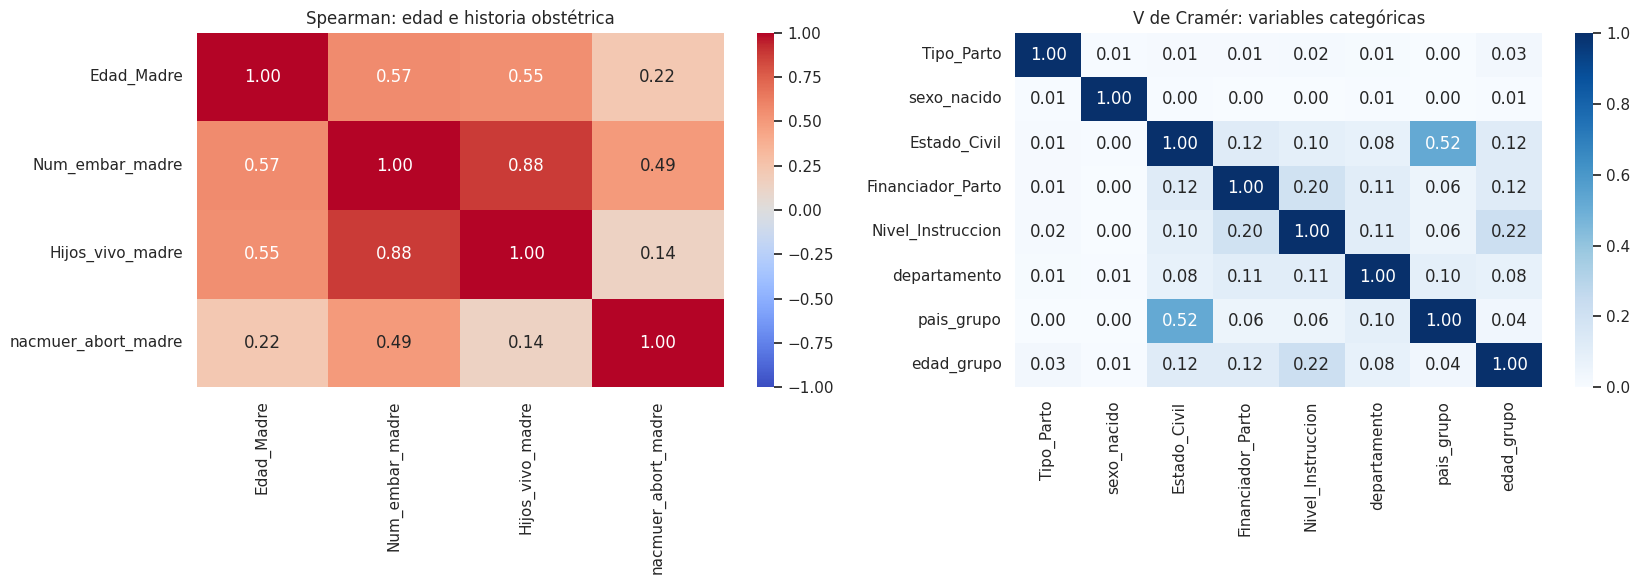

Spearman:
                     Edad_Madre  Num_embar_madre  Hijos_vivo_madre  nacmuer_abort_madre
Edad_Madre                1.000            0.566             0.551                0.225
Num_embar_madre           0.566            1.000             0.881                0.494
Hijos_vivo_madre          0.551            0.881             1.000                0.135
nacmuer_abort_madre       0.225            0.494             0.135                1.000


In [ ]:
spear = df_eda[["Edad_Madre"] + paridad].corr(method="spearman")

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

muestra = df_eda.sample(500_000, random_state=42)
cv_cols = ["Tipo_Parto", "sexo_nacido", "Estado_Civil", "Financiador_Parto", "Nivel_Instruccion", "departamento", "pais_grupo", "edad_grupo"]
cv = pd.DataFrame(index=cv_cols, columns=cv_cols, dtype=float)
for a in cv_cols:
    for b in cv_cols:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(muestra[a], muestra[b])

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(spear, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Spearman: edad e historia obstétrica")
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("V de Cramér: variables categóricas")
guardar("relaciones_features")
print("Spearman:"); print(spear.round(3).to_string())

**Interpretación** (valores de la matriz impresa):
- **`Num_embar_madre` y `Hijos_vivo_madre` son redundantes**, con una correlación de Spearman de ρ = 0.88. `Num_embar_madre` aporta algo más por sí sola (AUC de 0.531 frente a 0.524; ver sección 9).

  **Decisión:** se conserva solo `Num_embar_madre`, que contiene casi toda la información de ambas. Es la misma elección que hace Almeida et al. (2026), que usa una sola variable de paridad.
- `Num_embar_madre` y `nacmuer_abort_madre` tienen una correlación moderada (ρ = 0.49), lo cual es coherente con que el número de embarazos incluye los que terminaron en aborto. La edad y la paridad también se correlacionan moderadamente (ρ ≈ 0.55–0.57). Ninguno de estos casos es redundancia, así que se mantienen.
- Entre las variables categóricas, todas las asociaciones son débiles (V de Cramér ≤ 0.22). La más alta es entre nivel de instrucción y grupo de edad. Cada variable aporta información distinta.

## 9. Justificación de los escenarios A y B

El proyecto evalúa los modelos en dos escenarios que responden a preguntas distintas:

- **Escenario A (prenatal):** ¿se puede estimar el riesgo de bajo peso solo con información disponible antes del parto? Es la pregunta central del proyecto.
- **Escenario B (factores asociados):** agrega `DUR_EMB_PARTO`, la variable que usa el paper de referencia (Almeida et al. (2026), SINASC). Este escenario permite comparar los resultados con los del paper y medir cuánto del rendimiento depende de la edad gestacional.

`DUR_EMB_PARTO` se excluye del Escenario A por **leakage temporal**, no directo. La edad gestacional sí se estima durante el embarazo, por la fecha de última menstruación o por ecografía. Lo que no se conoce antes del parto es su valor final, es decir, si el nacimiento será pretérmino. Ese es justamente el dato que más información aporta sobre el bajo peso.

Esta sección cuantifica cuánto domina esa variable, comparando su poder discriminante (AUC-ROC de la variable sola) con el de las features prenatales.

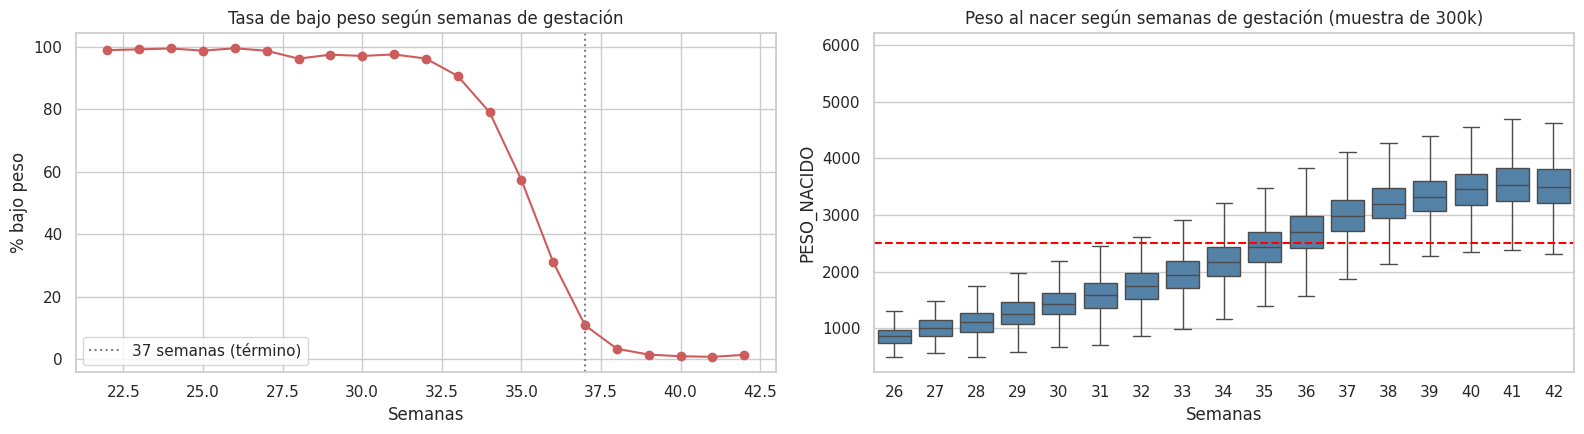

Tasa de bajo peso por semana de gestación (%):
DUR_EMB_PARTO
22.000   98.800
23.000   99.100
24.000   99.400
25.000   98.700
26.000   99.400
27.000   98.600
28.000   96.100
29.000   97.400
30.000   97.000
31.000   97.500
32.000   96.200
33.000   90.600
34.000   79.000
35.000   57.300
36.000   31.000
37.000   10.800
38.000    3.300
39.000    1.400
40.000    0.900
41.000    0.700
42.000    1.300
Partos pretérmino (<37 sem): 6.9% de los registros
Bajo peso en pretérmino:     57.9%
Bajo peso a término (≥37):   2.6%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
g = df_eda.groupby("DUR_EMB_PARTO")["bajo_peso"].agg(["mean", "count"])
g = g[g["count"] >= 300]
axes[0].plot(g.index, g["mean"] * 100, marker="o", color="indianred")
axes[0].axvline(37, color="gray", ls=":", label="37 semanas (término)")
axes[0].set_title("Tasa de bajo peso según semanas de gestación")
axes[0].set_xlabel("Semanas"); axes[0].set_ylabel("% bajo peso"); axes[0].legend()

m = df_eda[["DUR_EMB_PARTO", "PESO_NACIDO"]].dropna().sample(300_000, random_state=42)
m = m[m["DUR_EMB_PARTO"].between(26, 43)]
sns.boxplot(x=m["DUR_EMB_PARTO"].astype(int), y=m["PESO_NACIDO"], ax=axes[1], color="steelblue", fliersize=0)
axes[1].axhline(2500, color="red", ls="--")
axes[1].set_title("Peso al nacer según semanas de gestación (muestra de 300k)"); axes[1].set_xlabel("Semanas")
guardar("escenario_b_gestacion")

print("Tasa de bajo peso por semana de gestación (%):")
print((g["mean"] * 100).round(1).to_string())

pre = df_eda["DUR_EMB_PARTO"] < 37
print(f"Partos pretérmino (<37 sem): {pre.mean()*100:.1f}% de los registros")
print(f"Bajo peso en pretérmino:     {df_eda.loc[pre, 'bajo_peso'].mean()*100:.1f}%")
print(f"Bajo peso a término (≥37):   {df_eda.loc[df_eda['DUR_EMB_PARTO'] >= 37, 'bajo_peso'].mean()*100:.1f}%")

In [ ]:
def auc_univariado(col):
    """AUC de un clasificador trivial que asigna a cada registro la tasa de bajo peso de su categoría.
    Captura relaciones no lineales (p. ej., la forma en U de la edad)."""
    d = df_eda[[col, "bajo_peso"]].dropna()
    score = d.groupby(col, observed=True)["bajo_peso"].transform("mean")
    return roc_auc_score(d["bajo_peso"], score)

cand = ["DUR_EMB_PARTO", "Tipo_Parto", "Edad_Madre", "Nivel_Instruccion", "departamento", "Financiador_Parto",
        "Num_embar_madre", "Hijos_vivo_madre", "nacmuer_abort_madre", "sexo_nacido", "Estado_Civil", "pais_grupo"]
auc_tabla = pd.Series({c: auc_univariado(c) for c in cand}).sort_values(ascending=False).to_frame("AUC_univariado")
excluidas = ["Estado_Civil", "Hijos_vivo_madre"]   # se muestran como evidencia de su exclusión (secciones 4.6 y 8)
auc_tabla["escenario"] = np.select([auc_tabla.index == "DUR_EMB_PARTO", auc_tabla.index.isin(excluidas)],
                                   ["Solo B", "Excluida"], default="A y B")
auc_tabla

,AUC_univariado,escenario
DUR_EMB_PARTO,0.888,Solo B
Tipo_Parto,0.576,A y B
Edad_Madre,0.552,A y B
departamento,0.551,A y B
Num_embar_madre,0.531,A y B
Nivel_Instruccion,0.530,A y B
Hijos_vivo_madre,0.524,Excluida
Financiador_Parto,0.520,A y B
sexo_nacido,0.514,A y B
nacmuer_abort_madre,0.506,A y B


**Interpretación.**
- La edad gestacional explica la mayor parte del bajo peso. El 6.9% de los partos son pretérmino, y entre ellos el bajo peso llega a 57.9%, frente a 2.6% en los partos a término. La tabla por semana muestra que hasta la semana 33 el bajo peso supera el 90%, y desde la semana 38 cae por debajo del 3.5%.
- `DUR_EMB_PARTO` alcanza por sí sola un **AUC de 0.888**. La mejor variable prenatal, `Tipo_Parto`, llega a 0.576, y las demás están entre 0.50 y 0.55.
- `pais_grupo` tiene un AUC de solo 0.504 pese a la diferencia de tasas de la sección 7, porque afecta a muy pocos registros. Un AUC univariado bajo no significa que una variable sea inútil: mide su capacidad de ordenar a toda la población, no a un subgrupo.

**Implicaciones:**
1. El Escenario B tendrá métricas muy superiores, pero no porque el modelo prediga mejor, sino porque la duración final del embarazo es casi un sustituto del resultado. Sus métricas son las comparables con Almeida et al.; las del Escenario A miden la capacidad predictiva prenatal real. La diferencia entre ambos escenarios es en sí misma un resultado del proyecto.
2. El Escenario A, que representa la predicción prenatal real, tendrá un rendimiento modesto. Su valor está en combinar varias señales débiles.
3. El techo del Escenario A está limitado por las variables que registra el CNV, listadas en la sección 3. Por ejemplo, el dataset usado por Aftab et al. (2026), uno de los papers revisados, incluye visitas prenatales, anemia, hipertensión y aumento de peso materno, y el CNV no registra ninguna de ellas.

*Nota: el AUC univariado se calcula sobre todo el dataset con fines descriptivos. La evaluación de los modelos se hará sobre un conjunto de test separado.*

## 10. Conclusiones y decisiones de preprocesamiento

### Hallazgos y decisiones

| # | Hallazgo | Decisión (se implementa en `src/preprocessing.py`) |
|---|---|---|
| 1 | 388 filas con `;` dentro de `DESC_OCUPACION` | Reparar al cargar; no descartar filas |
| 2 | `Hijos_fallec_madre` con 97% de `-1` y significado ambiguo | Excluir |
| 3 | `-1`, `IGNORADO` y `99` son códigos de faltante | Convertir a `NaN` |
| 4 | Faltantes ≤ 8.6%, no asociados al target | Eliminación de casos completos (se conserva el 89.5%) |
| 5 | Valores fuera de rango (< 0.1%) | Convertir a `NaN`; eliminar registros sin peso válido |
| 6 | 974 duplicados sin ID que los distinga | Mantener |
| 7 | 0.60% de partos únicos con más hijos vivos que embarazos | Mantener; reportar como limitación |
| 8 | `Estado_Civil` poco creíble; 78.7% faltante en madres de 17 años o menos | Excluir del modelo base |
| 9 | Prevalencia de 6.38% (1:15) | Split estratificado, ponderación de clases, métricas recall / F1 / AUC-ROC |
| 10 | Redondeo de dígitos en 2500 g | Mantener umbral OMS; reportar como limitación |
| 11 | Edad materna con relación en U | Representarla de forma que capture la U (p. ej., grupos de edad) |
| 12 | Categorías raras | Agrupar partos múltiples, sanidades e "inicial" con "ningún nivel" |
| 13 | `Num_embar_madre` y `Hijos_vivo_madre` con ρ = 0.88 | Conservar solo `Num_embar_madre` |
| 14 | Ubigeo con 1892 distritos | Agregar a 25 departamentos; one-hot |
| 15 | `DUR_EMB_PARTO` con AUC de 0.89 | Solo en Escenario B |
| 16 | Prevalencia sube de 6.0% a 6.9% entre 2020 y 2023 | Split aleatorio; validación temporal como prueba opcional |
| 17 | Madres venezolanas con 8.2% de bajo peso frente a 6.3% | Incorporar `pais_grupo` (Perú / Venezuela / Otro) |
| 18 | Variables numéricas con ρ < 0.10 respecto del peso | Esperar R² bajo en regresión del Escenario A; reportarlo |

### Features finales

- **Escenario A (prenatal):** `Edad_Madre`, `Nivel_Instruccion`, `Financiador_Parto`, `Tipo_Parto`, `sexo_nacido`, `departamento`, `pais_grupo`, `Num_embar_madre`, `nacmuer_abort_madre`.
- **Excluidas tras el análisis:** `Estado_Civil` (4.6), `Hijos_fallec_madre` (4.2), `Hijos_vivo_madre` (8).
- **Escenario B:** las del Escenario A más `DUR_EMB_PARTO`.

### Limitaciones del dataset

El CNV es un registro administrativo, no un instrumento clínico. Tiene errores de digitación (sección 4.3), inconsistencias en la historia obstétrica (4.5), redondeo del peso (5) y variables con validez dudosa, como el estado civil (4.6). Además, no registra variables clínicas que sí usan otros estudios revisados, como visitas prenatales, anemia o hipertensión materna (sección 9). Por eso es esperable que el Escenario A tenga un rendimiento limitado.
